
#**Diplomatura en Ciencia de Datos, Aprendizaje Automático y sus Aplicaciones**

##**Edición 2026**

---
## Trabajo práctico entregable - Parte 1

## GRUPO 5

Integrantes: Daniela Riego, Gerónimo Castro, Constanza Bencharski, Gerónimo Sequeiros

Fecha: 13/04/2026

In [ ]:
import io
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn

seaborn.set_context('talk')

## Lectura del dataset


In [ ]:
url = 'https://raw.githubusercontent.com/DiploDatos/AnalisisyVisualizacion/master/sysarmy_survey_2026_processed.csv'
df_raw = pd.read_csv(url)     # datos originales
df = df_raw.copy()            # dataset de trabajo

## Primera exploración
En primera instancia, analizamos el tamaño del dataset y sus distintos tipos de variables

In [ ]:
df.shape

(4939, 60)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4939 entries, 0 to 4938
Data columns (total 60 columns):
 #   Column                                                Non-Null Count  Dtype  
---  ------                                                --------------  -----  
 0   work_province                                         4939 non-null   object 
 1   work_dedication                                       4939 non-null   object 
 2   work_contract_type                                    4939 non-null   object 
 3   salary_monthly_BRUTO                                  4939 non-null   float64
 4   salary_monthly_NETO                                   4717 non-null   float64
 5   salary_in_usd                                         1583 non-null   object 
 6   salary_last_dollar_value                              1028 non-null   object 
 7   salary_has_bonus                                      4939 non-null   object 
 8   salary_bonus_tied_to                                  4938

# Ejercicio 1 - Análisis descriptivo

Responder a la pregunta: **¿Cuáles son los lenguajes de programación asociados a los mejores salarios?**

Para ello:
1. Seleccionar las columnas relevantes para analizar.
2. Seleccionar las filas relevantes para analizar. Esto incluye la eliminación de valores extremos y erróneos, pero también puede enfocar el análisis en una sub-población. Por ejemplo, se pueden limitar a personas con un salario mayor que 300000 pesos, o a las personas que trabajan sólo en "Data Science", pero deben justificar su elección y reformular la pregunta inicial de ser necesario.
  * Obtener una lista de los lenguajes de programación más populares. Decidir cuántos y cuáles seleccionan para incluir en el análisis.
  * Para cada una de las otras columnas del punto anterior, elegir los rangos o valores seleccionan para incluir en el análisis.
3. Seleccionar métricas que ayuden a responder la pregunta, y los métodos para analizarlas. Elegir UNA de las siguientes opciones:
  * Comparar las distribuciones de salario para cada lenguaje utilizando visualizaciones. Como la visualización es el producto final, debe ser clara y mostrar información relevante.
  * Comparar medidas de estadística descriptiva sobre la distribución de salario para cada lenguaje. Sean creativos, la estadística descriptiva nos permite decir cosas como: "el 10% de los mejores sueldos los ganan, en su mayoría, programadores que saben kotlin!" (donde *mayoría* es un término medio engañoso que sólo significa más del 50%). Para comparar múltiples lenguajes, les recomendamos usar también visualizaciones.
  * Comparar probabilidades. Por ejemplo: "Si sabés Python o Java, tenés un 30% más de chances de ganar arriba de 1000K".

Si lo consideran necesario, realicen varias iteraciones. Es decir, si encuentran que las distribuciones de los lenguajes de programación que seleccionaron inicialmente no son muy diferentes, pueden re-hacer el análisis usando sólo los lenguajes de programación que son diferentes.

##1. Selección de Columnas relevantes
Considerando que aún no se han visto herramientas para la selección de atributos (salvo visualización de datos), la elección de los mismos, en este caso, se ha hecho de manera cualitativa. Agragamos la columna **'work_dedication'** como relevante a las previamente ya seleccionadas **'tools_programming_languages'** y **'salary_monthly_NETO'**. Nos pareció que la dedicación del trabajor, siendo esta full time o part time, influye en gran medida sobre el salario percibido.

In [ ]:
relevant_columns = ['tools_programming_languages', 'salary_monthly_NETO','work_dedication']

Procedemos en primer lugar a visualizar el contenido las tres columnas relevantes:

In [ ]:
print(df[relevant_columns])

                            tools_programming_languages  salary_monthly_NETO  \
0        .NET, C#, CSS, Go, HTML, Java, Javascript, SQL            2400000.0   
1                       .NET, C#, HTML, Javascript, SQL            5000000.0   
2                                               Go, SQL            3600000.0   
3                             Ninguno de los anteriores            6000000.0   
4                                    Bash/Shell, Python            3200000.0   
...                                                 ...                  ...   
4934                          Ninguno de los anteriores            3740000.0   
4935                                             Python            1000000.0   
4936  Bash/Shell, HTML, Java, Javascript, PHP, Pytho...            2908000.0   
4937                  Java, Javascript, SQL, TypeScript            3400000.0   
4938                                        Python, SQL            3690000.0   

     work_dedication  
0          Full-

##2. Análisis y limpieza de datos

Analizamos cada atributo por separado, detectando así posibles datos erróneos o faltantes. Éste paso nos ayuda también a decidir sobre los intervalos o rangos de interés de cada sub-sampleo.  

In [ ]:
df['salary_monthly_NETO'].describe()

,salary_monthly_NETO
count,4.717000e+03
mean,3.599215e+06
std,1.183755e+07
min,1.600000e+00
25%,1.850000e+06
50%,2.750000e+06
75%,4.000000e+06
max,6.533882e+08


Observamos que la columna de salarios es obviamente una columna numérica, con valores mínimos y máximos muy extremos respecto a la media de mis datos. Para que éstos outliers no interfieran con mi analisis estadístico será necesario, más adelante, seleccionar rangos cuartiles de mi distribución total.

In [ ]:
df['tools_programming_languages'].unique()

array(['.NET, C#, CSS, Go, HTML, Java, Javascript, SQL',
       '.NET, C#, HTML, Javascript, SQL', 'Go, SQL', ...,
       'Bash/Shell, HTML, Javascript, PHP, Python, TypeScript',
       'Bash/Shell, CSS, HTML, Java, Javascript, Perl, PHP, Python, SQL, TypeScript',
       'HTML, Ruby, SQL, TypeScript'], dtype=object)

Vemos que la columna correspondiente a los lenguajes de programación contiene listas por cada fila, es decir cada persona que respondió a la encuenta puede saber más de un lenguaje de programación. La limpieza de los datos y el split de las listas para un trabajo más fácil se harán en pasos posteriores.

In [ ]:
df['work_dedication'].unique()

array(['Full-Time', 'Part-Time'], dtype=object)

In [ ]:
df['work_dedication'].value_counts()

,count
work_dedication,
Full-Time,4724
Part-Time,215


Para el caso de la columna de dedicación, vemos que se tratan de datos binarios, la columna solamente toma dos posibles valores: o Full time o Part time. No hay datos erróneos o vacíos que necesiten de limpieza. Además al hacer un conteo de cada valor de la variable observamos que la dedicación **Full-time** representa un 95.6% de los datos.


###Filtrado del 'salario' y 'dedicación'

Determinamos en primer lugar cuál es la cantidad de datos "NaN" en la columna del salario para el DataFrame, y su proporción en el total de los datos. Se observa que estos no representan más que el 5% de los datos.


In [ ]:
nan_salaries_count = df['salary_monthly_NETO'].isna().sum()
nan_prop = nan_salaries_count / len(df)
print(f'Cantidad de NaN en Salario Neto (Full Time o Part Time): {nan_salaries_count}')
print(f'Proporción de NaN en total de datos: {nan_prop}')
df_nan = df.dropna(subset=['salary_monthly_NETO'])

Cantidad de NaN en Salario Neto (Full Time o Part Time): 222
Proporción de NaN en total de datos: 0.044948370115407976


Mostramos la distribución de salarios 'cruda' en un quickplot

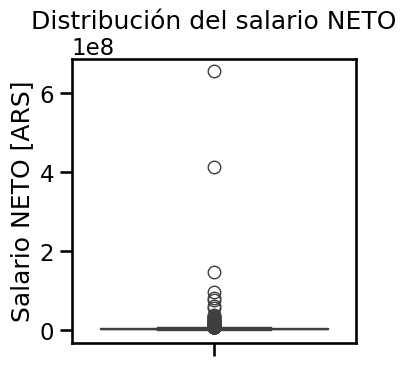

In [ ]:
plt.figure(figsize=(4, 4))

seaborn.boxplot(
    y=df_nan['salary_monthly_NETO']
)

plt.title('Distribución del salario NETO')
plt.ylabel('Salario NETO [ARS]')
plt.xlabel('')

plt.tight_layout()
plt.show()

Filtramos los outliers en el salario utilizando, en primera instancia, rangos intercuartílicos. Definiendo el percentil 25 y percentil 75 de forma que el IQR representa el 50% central.   



In [ ]:
Q1 = df_nan['salary_monthly_NETO'].quantile(0.25)
Q3 = df_nan['salary_monthly_NETO'].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Filtrar el DataFrame
df_sin_outliers = df_nan[(df_nan['salary_monthly_NETO'] >= limite_inferior) & (df_nan['salary_monthly_NETO'] <= limite_superior)]

In [ ]:
df_sin_outliers['salary_monthly_NETO'].describe()

,salary_monthly_NETO
count,4.479000e+03
mean,2.909935e+06
std,1.482143e+06
min,1.600000e+00
25%,1.800000e+06
50%,2.634641e+06
75%,3.800000e+06
max,7.211291e+06


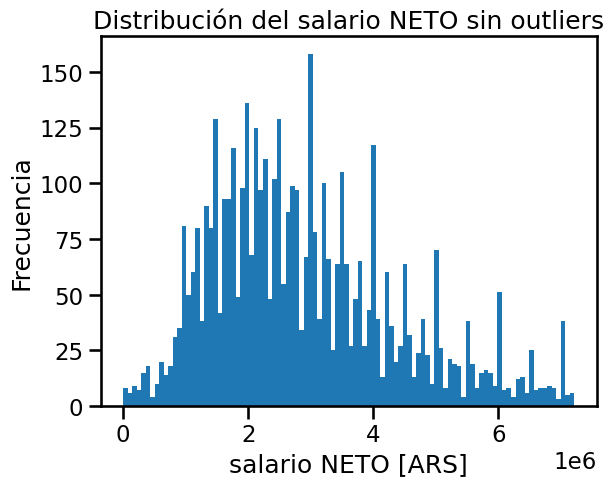

In [ ]:
df_sin_outliers.salary_monthly_NETO.plot(kind='hist', bins=100)
plt.xlabel('salario NETO [ARS]')
plt.ylabel('Frecuencia')
plt.title('Distribución del salario NETO sin outliers')
plt.show()

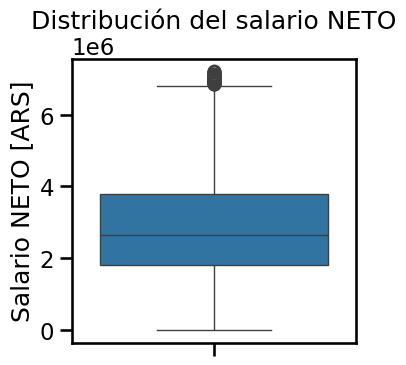

In [ ]:
plt.figure(figsize=(4, 4))

seaborn.boxplot(
    y=df_sin_outliers['salary_monthly_NETO']
)

plt.title('Distribución del salario NETO')
plt.ylabel('Salario NETO [ARS]')
plt.xlabel('')

plt.tight_layout()
plt.show()

Vemos que al tratarse de una distribución con una cola a derecha muy larga (por valores irreales muy altos) el IQR es grande y el límite inferior resulta muy permisivo admitiendo valores cercanos al 0, lo cuál no nos sirve para el análisis.  

In [ ]:
# Analizamos el tamaño del dataframe filtrado con criterio IQR
df_sin_outliers.shape

(4479, 60)

Al hacer este filtrado nos quedamos con un 91% de los datos originales

Finalmente decidimos tomar un rango de valores de salarios que sean mayores a 357.800, que corresponden a un salario mínimo, según el salario mínimo vital y móvil hasta abril del 2026 en Argentina, y menores a 20.000.000 dado que, según lo que se visualiza en la distribución de dicha variable, rangos por afuera de este intervalo corresponden a la cola de la distribución, siendo casos muy raros y poco realistas.

Respecto a la dedicación nos quedamos solo con los "Full-Time" sabiendo que representan un 95% de los datos.   

In [ ]:
print('Máximo sin filtrar',max(df_nan['salary_monthly_NETO']),'Mínimo sin filtrar',min(df_nan['salary_monthly_NETO']))
#Filtramos el rango seleccionado y nos quedamos solo con los "Full-Time"
df1= df_nan[(df_nan['salary_monthly_NETO'] < 20000000) &  (df_nan['salary_monthly_NETO'] > 357800) & (df_nan['work_dedication'] == 'Full-Time')].copy()
print('Máximo filtrado',max(df1['salary_monthly_NETO']),'Mínimo filtrado',min(df1['salary_monthly_NETO']))

Máximo sin filtrar 653388190.0 Mínimo sin filtrar 1.6
Máximo filtrado 19000000.0 Mínimo filtrado 360000.0


In [ ]:
df1.shape

(4462, 60)

Filtrando el dataframe de esta forma nos quedamos ocn el 90.3% de los datos originales.

### Conteo de frecuencias de los lenguajes de programación



La columna que contiene información sobre los lenguajes de programación utilizados es `tools_programming_languages`. Sus valores son strings con los lenguajes seleccionados separados por comas.

In [ ]:
df1.tools_programming_languages[:3]

,tools_programming_languages
0,".NET, C#, CSS, Go, HTML, Java, Javascript, SQL"
1,".NET, C#, HTML, Javascript, SQL"
2,"Go, SQL"


Las siguientes celdas de código separan estos lenguajes de programación y cuentan la frecuencia con la que aparecen.

In [ ]:
# Convert the comma-separated string of languages to a list of string.
# Remove 'ninguno de los anteriores' option, spaces and training commas.
def split_languages(languages_str):
  if not isinstance(languages_str, str):
    return []
  # Remove 'other' option
  languages_str = languages_str.lower()\
    .replace('ninguno de los anteriores', '')
  # Split string into list of items
  # Remove spaces and commas for each item
  return [lang.strip().replace(',', '')
          for lang in languages_str.split()]

# Create a new column with the list of languages
df1.loc[:, 'cured_programming_languages'] = df1.tools_programming_languages\
    .apply(split_languages)
if 'cured_programming_languages' not in relevant_columns:
    relevant_columns.append('cured_programming_languages')

# Duplicate each row of df for each programming language
# mentioned in the response.
# We only include in df_lang the columns we are going to analyze later, so we
# don't duplicate innecesary information.
df1_lang = df1.cured_programming_languages\
    .apply(pd.Series).stack()\
    .reset_index(level=-1, drop=True).to_frame()\
    .join(df1[relevant_columns])\
    .rename(columns={0: 'programming_language'})
# Horrible programming style! But a lot of data science code can be written with
# as concatenations of functions (pipelines), and there's no elegant way of
# doing that on Python.
df1_lang[:5]

,programming_language,tools_programming_languages,salary_monthly_NETO,work_dedication,cured_programming_languages
0,.net,".NET, C#, CSS, Go, HTML, Java, Javascript, SQL",2400000.0,Full-Time,"[.net, c#, css, go, html, java, javascript, sql]"
0,c#,".NET, C#, CSS, Go, HTML, Java, Javascript, SQL",2400000.0,Full-Time,"[.net, c#, css, go, html, java, javascript, sql]"
0,css,".NET, C#, CSS, Go, HTML, Java, Javascript, SQL",2400000.0,Full-Time,"[.net, c#, css, go, html, java, javascript, sql]"
0,go,".NET, C#, CSS, Go, HTML, Java, Javascript, SQL",2400000.0,Full-Time,"[.net, c#, css, go, html, java, javascript, sql]"
0,html,".NET, C#, CSS, Go, HTML, Java, Javascript, SQL",2400000.0,Full-Time,"[.net, c#, css, go, html, java, javascript, sql]"


En la columna `programming_language` se encuentra cada lenguaje por separado. Notar que si una respuesta contenía 3 lenguajes, como `"HTML, Javascript, Python"`, la fila ha sido replicada 3 veces. Por ello, hay tres filas con índice 1.

In [ ]:
language_count = df1_lang.programming_language.value_counts()\
    .reset_index()\
    .rename(columns={'index': 'language', 'programming_language': 'frequency'})
language_count[:12]

,frequency,count
0,sql,2019
1,javascript,1684
2,python,1602
3,html,1240
4,typescript,1034
5,bash/shell,801
6,css,786
7,java,726
8,php,498
9,.net,494


## Filtrado de lenguajes relevantes
Se seleccionaron los lenguajes de programación a analizar de manera tal que estos representen el 80% del total de los datos.

In [ ]:
proporciones = df1_lang['programming_language'].value_counts(normalize=True)
acumulado = proporciones.cumsum()

porcent_validos = acumulado[acumulado <= 0.8].index.tolist()

df1_lang_filtrado_porcent = df1_lang[df1_lang['programming_language'].isin(porcent_validos)]

print(f"Los lenguajes de programación que contienen aproximadamente el 80% de los datos son: {porcent_validos}")


Los lenguajes de programación que contienen aproximadamente el 80% de los datos son: ['sql', 'javascript', 'python', 'html', 'typescript', 'bash/shell', 'css', 'java']


Verificamos que el nuevo dataframe contenga solo los lenguajes relevantes en la columna correspondiente.

In [ ]:
df1_lang_filtrado_porcent['programming_language'].unique()

array(['css', 'html', 'java', 'javascript', 'sql', 'bash/shell', 'python',
       'typescript'], dtype=object)

Verificamos que al quedarnos con estos lenguajes de programación nos quedemos con un porcentaje representativo.

In [ ]:
# porcentaje sobre el total inicial es el 80% (resultante de los lenguajes) del 90.3% de los datos filtrados
porcentaje = 0.8*90.3
porcentaje

72.24

Visualizamos los datos:

In [ ]:
language_count = df1_lang_filtrado_porcent['programming_language'].value_counts().reset_index()
language_count.columns = ['programming_language', 'count']

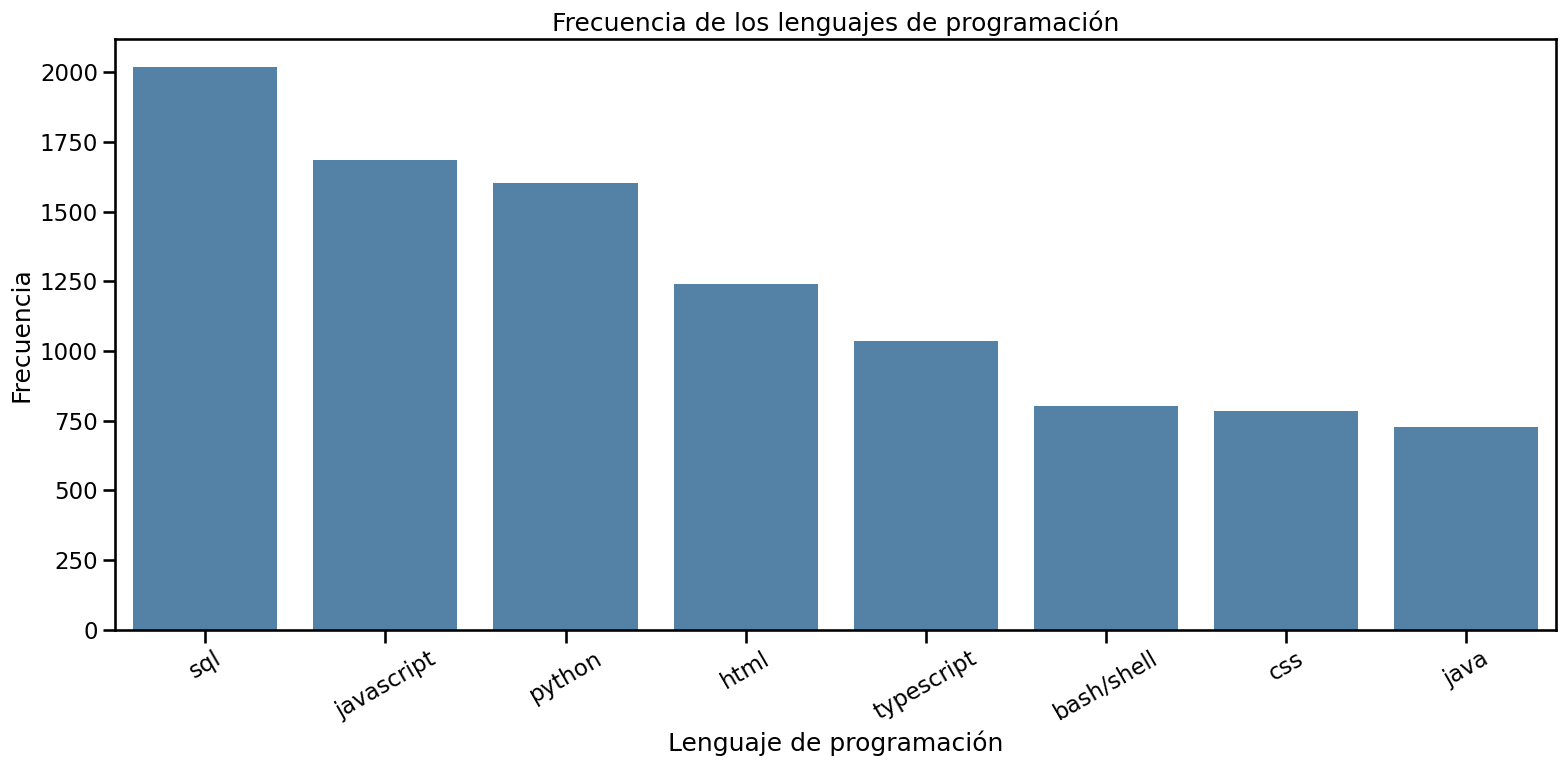

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(16,8))
seaborn.barplot(x='programming_language', y='count', data=language_count[:8], color='steelblue')
plt.xlabel('Lenguaje de programación')
plt.ylabel('Frecuencia')
plt.title('Frecuencia de los lenguajes de programación')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Y finalmente, creamos una lista de los lenguajes de interés.

In [ ]:
interesting_languages = df1_lang_filtrado_porcent.programming_language.value_counts()[:8].index.tolist()

##Visualización
Graficamos las distribuciones de salario neto para cada lenguaje de programación seleccionado.

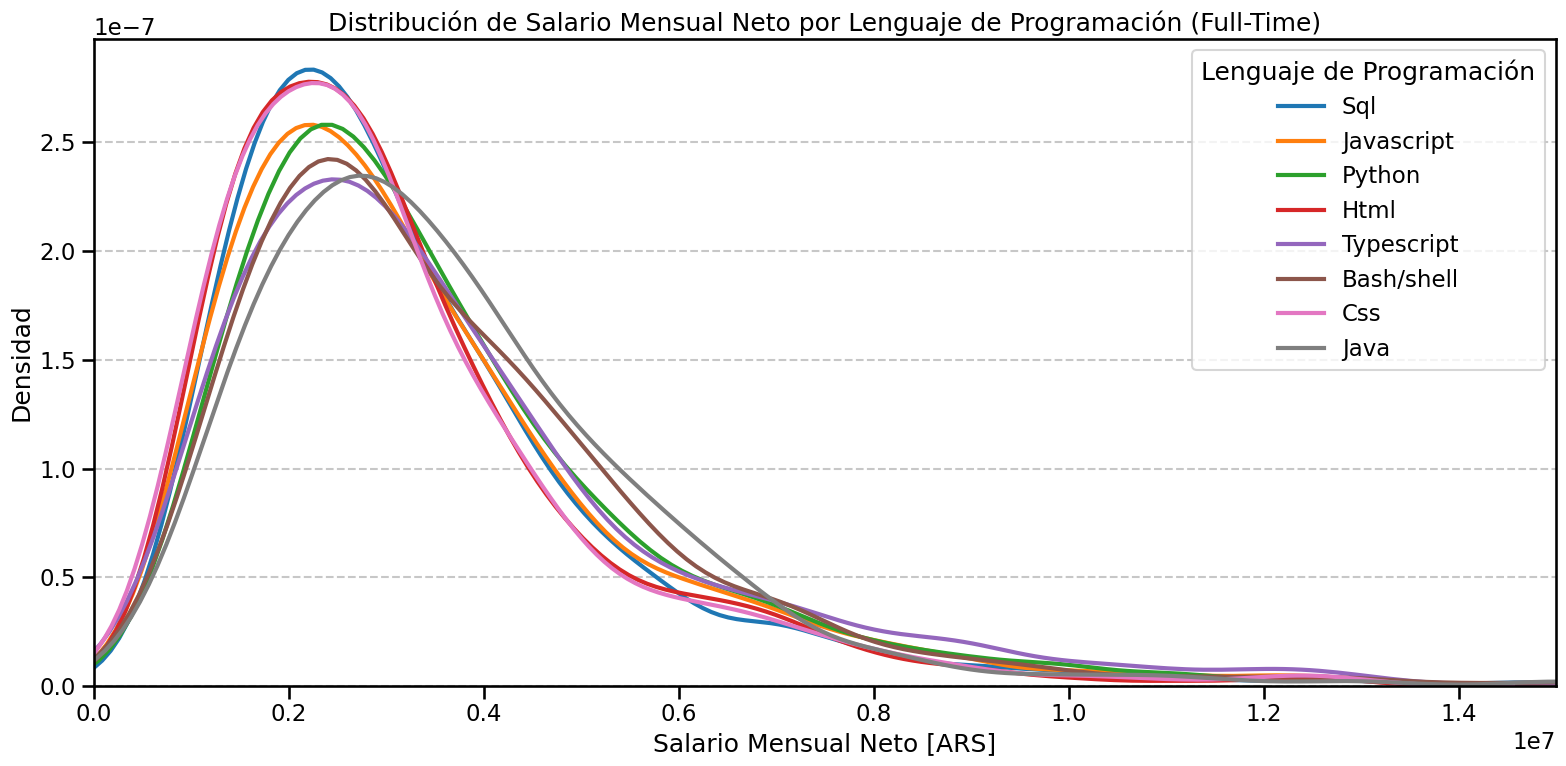

In [ ]:
plt.figure(figsize=(16, 8))

for lang in interesting_languages:
    seaborn.kdeplot(
        data=df1_lang_filtrado_porcent[
            df1_lang_filtrado_porcent['programming_language'] == lang],
            x='salary_monthly_NETO',
            label=lang.capitalize(),
            linewidth=3
    )

plt.title('Distribución de Salario Mensual Neto por Lenguaje de Programación (Full-Time)')
plt.xlabel('Salario Mensual Neto [ARS]')
plt.ylabel('Densidad')
plt.legend(title='Lenguaje de Programación')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.xlim(0, 15000000)
plt.show()

A partir de un análisis cualitativo de este gráfico de curvas podemos que ver que el lenguaje 'Java' tiene una distribución corrida a la derecha, es decir, salarios mayores respecto del resto de lenguajes.

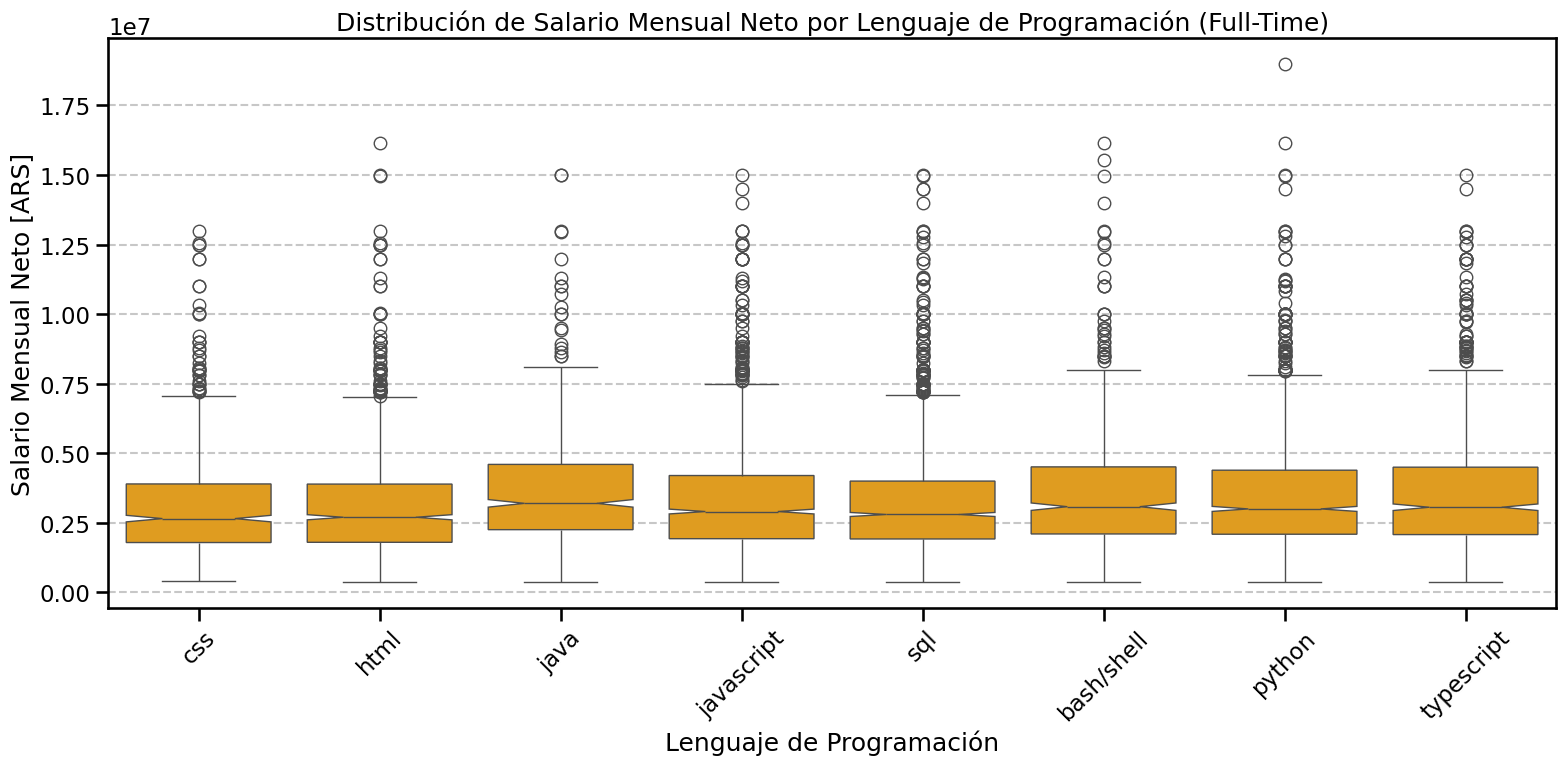

In [ ]:
plt.figure(figsize=(16, 8))
seaborn.boxplot(x='programming_language', y='salary_monthly_NETO', data=df1_lang_filtrado_porcent, color='orange', notch=True)
plt.title('Distribución de Salario Mensual Neto por Lenguaje de Programación (Full-Time)')
plt.xlabel('Lenguaje de Programación')
plt.ylabel('Salario Mensual Neto [ARS]')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Hacemo sun zoom para analizar las medianas con los intervalos de confianza. Si los intervalos de confianza se superponen las medianas son indistinguibles.



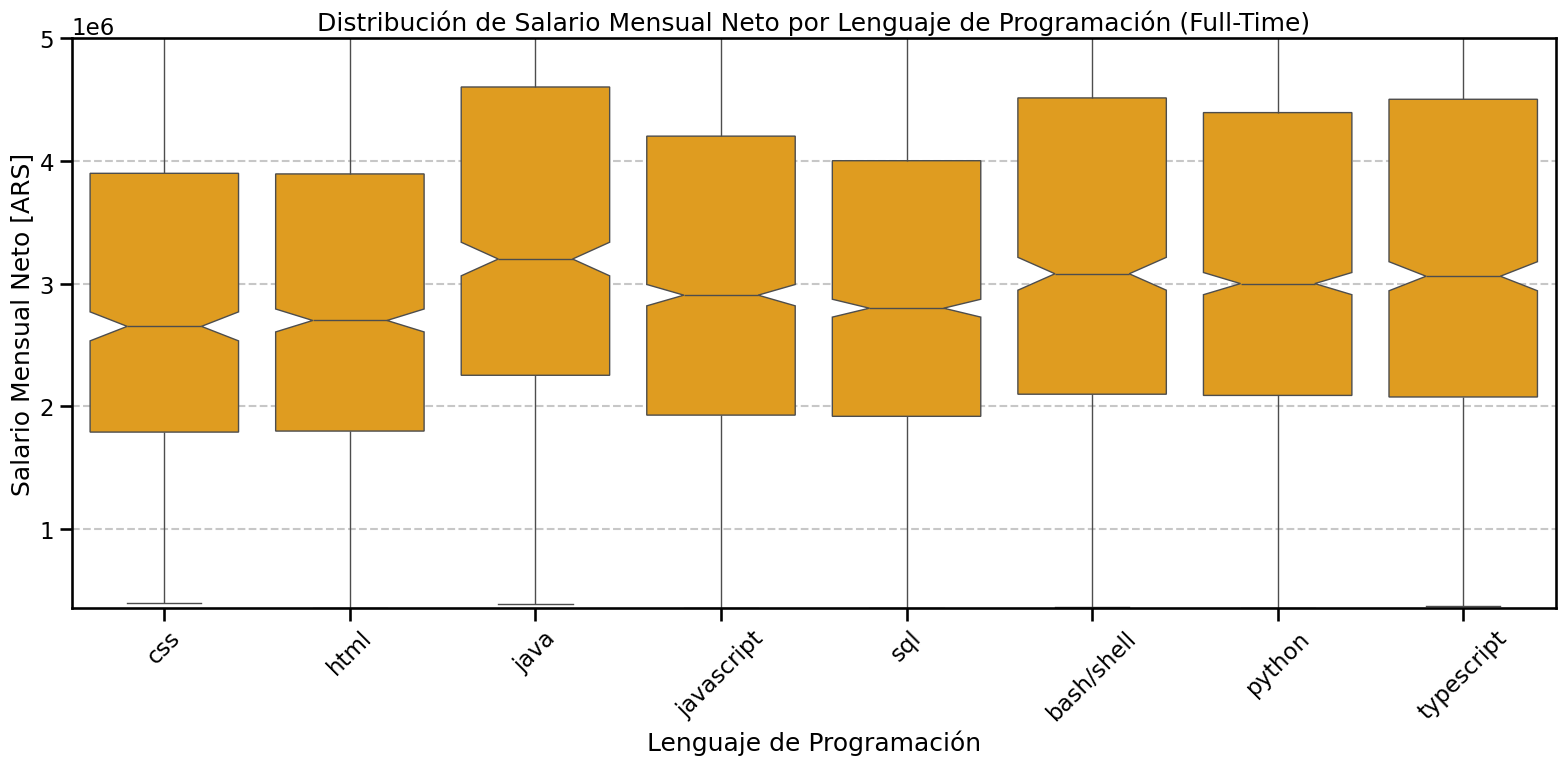

In [ ]:
plt.figure(figsize=(16, 8))
seaborn.boxplot(x='programming_language', y='salary_monthly_NETO', data=df1_lang_filtrado_porcent, color='orange', notch=True)
plt.title('Distribución de Salario Mensual Neto por Lenguaje de Programación (Full-Time)')
plt.xlabel('Lenguaje de Programación')
plt.ylabel('Salario Mensual Neto [ARS]')
plt.xticks(rotation=45)
plt.ylim(357800, 5E6)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Observamos que la mediana del salario para el caso de java es distinguible con respecto a css, html y javascript.

## Estadísticos y Probabilidades
Calculamos la probabilidad de cobrar más que la media y comparamos con la probabilidad de cobrar más que la media dado que el encuestado conoce un lenguaje de programacion en particular.

In [ ]:
avg_salary = df1_lang_filtrado_porcent['salary_monthly_NETO'].mean()  #salario promedio
print('Salario promedio:',avg_salary)

Salario promedio: 3423295.3327658717


In [ ]:
prob_above_avg = len(df1_lang_filtrado_porcent[df1_lang_filtrado_porcent['salary_monthly_NETO'] >= avg_salary]) / len(df1_lang_filtrado_porcent) #cobrar más que el promedio
print('Probabilidad de cobrar más que el promedio:', prob_above_avg)

Probabilidad de cobrar más que el promedio: 0.3843509906995552


Calculamos la probabilidad condicional de cobrar más que el promedio sabiendo cada lenguaje relevante. Estos valores se observan en la tabla final.

In [ ]:
tabla_porcentajes = []

is_above_avg = df1_lang_filtrado_porcent['salary_monthly_NETO']> avg_salary
for language in porcent_validos:
    sql_language = df1_lang_filtrado_porcent['programming_language'].isin([language])

    intersection_count = len(df1_lang_filtrado_porcent[is_above_avg & sql_language])
    sql_language_count=len(df1_lang_filtrado_porcent[sql_language])

    prob_cond_above_avg_dada_exp=len(df1_lang_filtrado_porcent[is_above_avg & sql_language])/len(df1_lang_filtrado_porcent[sql_language])

    tabla_porcentajes.append({'Lenguaje': language, 'Prob_condicional': prob_cond_above_avg_dada_exp})

df_probabilidades = pd.DataFrame(tabla_porcentajes)
df_probabilidades

,Lenguaje,Prob_condicional
0,sql,0.354631
1,javascript,0.383610
2,python,0.409488
3,html,0.329839
4,typescript,0.421663
5,bash/shell,0.434457
6,css,0.318066
7,java,0.469697


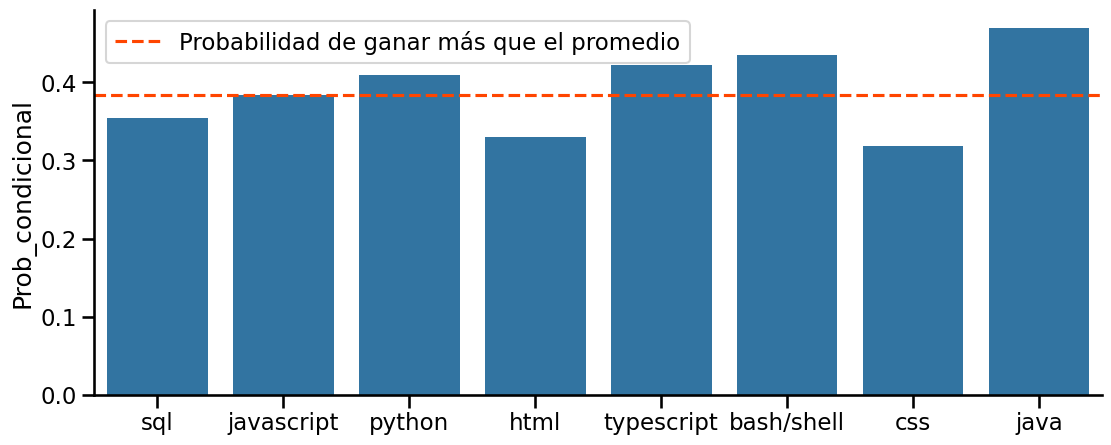

In [ ]:
plt.figure(figsize=(13, 5))

seaborn.barplot(x = interesting_languages, y=df_probabilidades.Prob_condicional)

plt.axhline(prob_above_avg,
            color='orangered', linestyle='--', label='Probabilidad de ganar más que el promedio')
plt.legend()
seaborn.despine()
plt.show()

## Conclusiones:
Podemos decir entonces que el único lenguaje con una diferencia significativa entre la probabilidad condicional evaluada y la marginal (mayor al 5%) es 'Java'. Esto se traduce en que quizás saber dicho lenguaje aumenta las probabilidades de cobrar un salario por encima de la media.  





# Ejercicio 2 - Densidades y varias variables

Responder a la pregunta general: **¿Que herramientas (prácticas y teóricas) són útiles para explorar la base, descubrir patrones, asociaciones?**

Para ello considere (igual al ejercicio Anterior):
1. Seleccionar las columnas relevantes para analizar.
2. Seleccionar las filas relevantes para analizar. Esto incluye la eliminación de valores extremos y erróneos, pero también puede enfocar el análisis en sub-poblaciones.

## a) Densidad conjunta

Que herramientas visuales y modelos puede utilizar para estudiar la distribución y comportamiento de sus datos?

Elija tres variables numéricas y 2 variables categóricas. Visualice la base según varias de las variables elegidas. Puede describir de alguna forma el comportamiento de sus datos? Que herramientas utilizaría? Describa






## b) Asociación

* Necesitamos decidir si sacar o no la columna de salario bruto. Para hacer la encuesta más simple.
¿Existe una correlación entre el salario bruto y el neto? Que abordaje y medidas usaría



## c) Densidad condicional

Estudie la distribución del salario según el nivel de estudio.

Separe la población según el nivel de estudio (elija dos subpoblaciones numerosas) y grafique de manera comparativa ambos histogramas de la variable `'salary_monthly_NETO'`
¿Considera que ambas variables son independientes?
¿Qué analizaría al respecto?

Calcule medidas de centralización y dispersión para cada subpoblación






## d) Densidad Conjunta condicional

Elija dos variables numéricas y una categórica.
Estudie la dispersión (scatterplot) de las dos variables discriminando en color por la variable categórica (ayuda: hue en seaborn)


# Punto 2 a)
Densidad conjunta.

Que herramientas visuales y modelos puede utilizar para estudiar la distribución y comportamiento de sus datos? \
Elija tres variables numéricas y 2 variables categóricas. Visualice la base según varias de las variables elegidas. Puede describir de alguna forma el comportamiento de sus datos? Que herramientas utilizaría? Describa

Definimos nuevas variables de interes: provincia, salario NETO, salario BRUTO, genero y años de experiencia

### Columnas numéricas

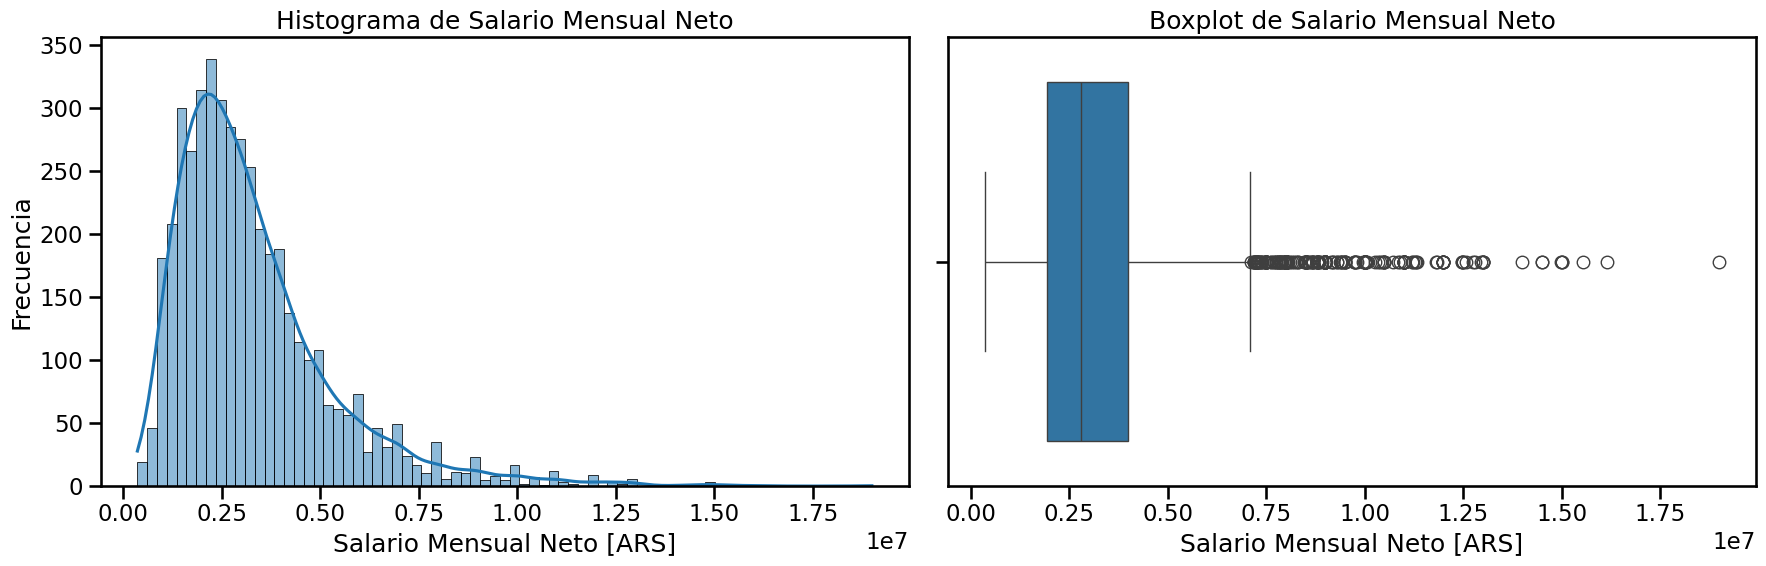

In [ ]:
# VISUALIZAMOS EL NETO YA FILTRADO DEL PUNTO 1

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Histograma en el panel izquierdo
seaborn.histplot(df1['salary_monthly_NETO'], kde=True, ax=axes[0])
axes[0].set_title('Histograma de Salario Mensual Neto')
axes[0].set_xlabel('Salario Mensual Neto [ARS]')
axes[0].set_ylabel('Frecuencia')

# Boxplot en el panel derecho
seaborn.boxplot(x=df1['salary_monthly_NETO'], ax=axes[1])
axes[1].set_title('Boxplot de Salario Mensual Neto')
axes[1].set_xlabel('Salario Mensual Neto [ARS]')

plt.tight_layout()
plt.show()

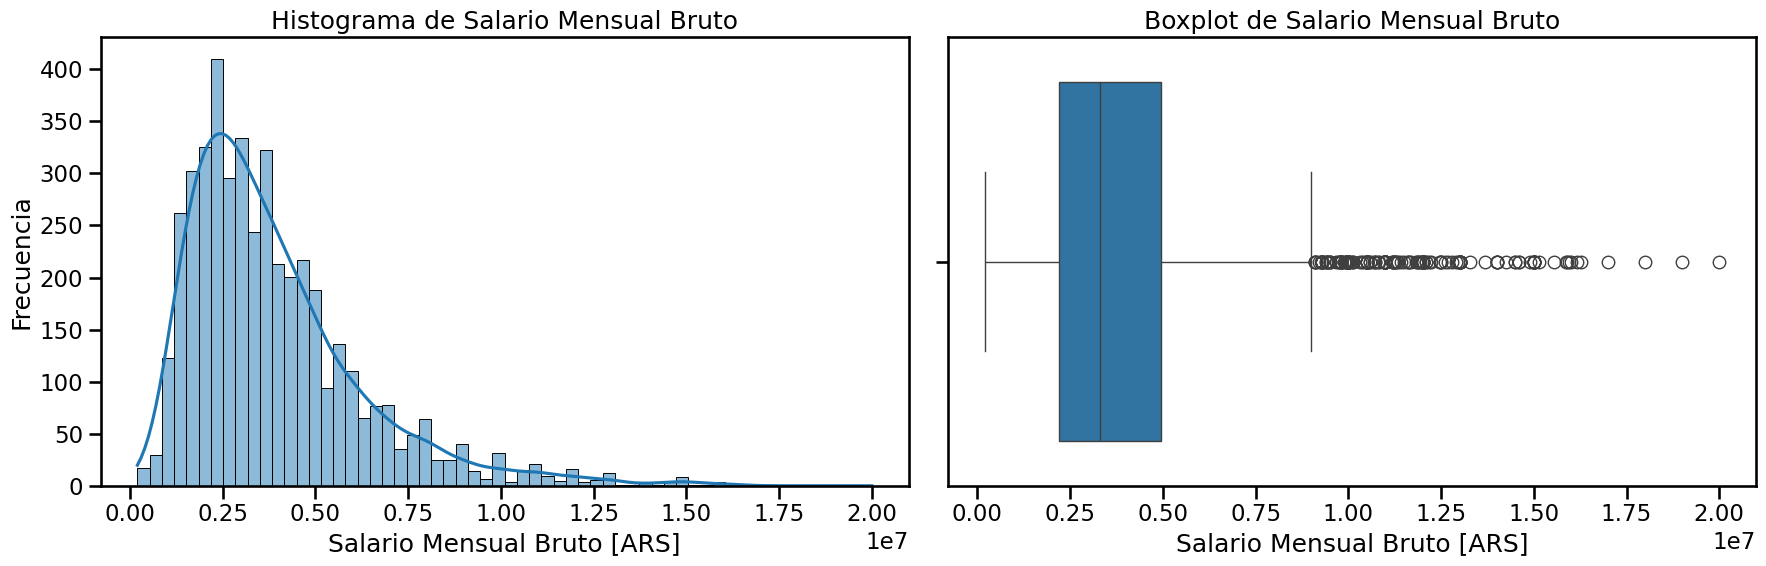

In [ ]:
# VISUALIZAMOS EL SALARIO BRUTO

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Histograma en el panel izquierdo
seaborn.histplot(df1['salary_monthly_BRUTO'], kde=True, ax=axes[0])
axes[0].set_title('Histograma de Salario Mensual Bruto')
axes[0].set_xlabel('Salario Mensual Bruto [ARS]')
axes[0].set_ylabel('Frecuencia')

# Boxplot en el panel derecho
seaborn.boxplot(x=df1['salary_monthly_BRUTO'], ax=axes[1])
axes[1].set_title('Boxplot de Salario Mensual Bruto')
axes[1].set_xlabel('Salario Mensual Bruto [ARS]')

plt.tight_layout()
plt.show()

En estos gráficos visualizamos los datos del salario bruto asociados a los salarios netos que fueron filtrados con el criterio de estar en el rango 300mil - 20 millones, como en el punto 1.

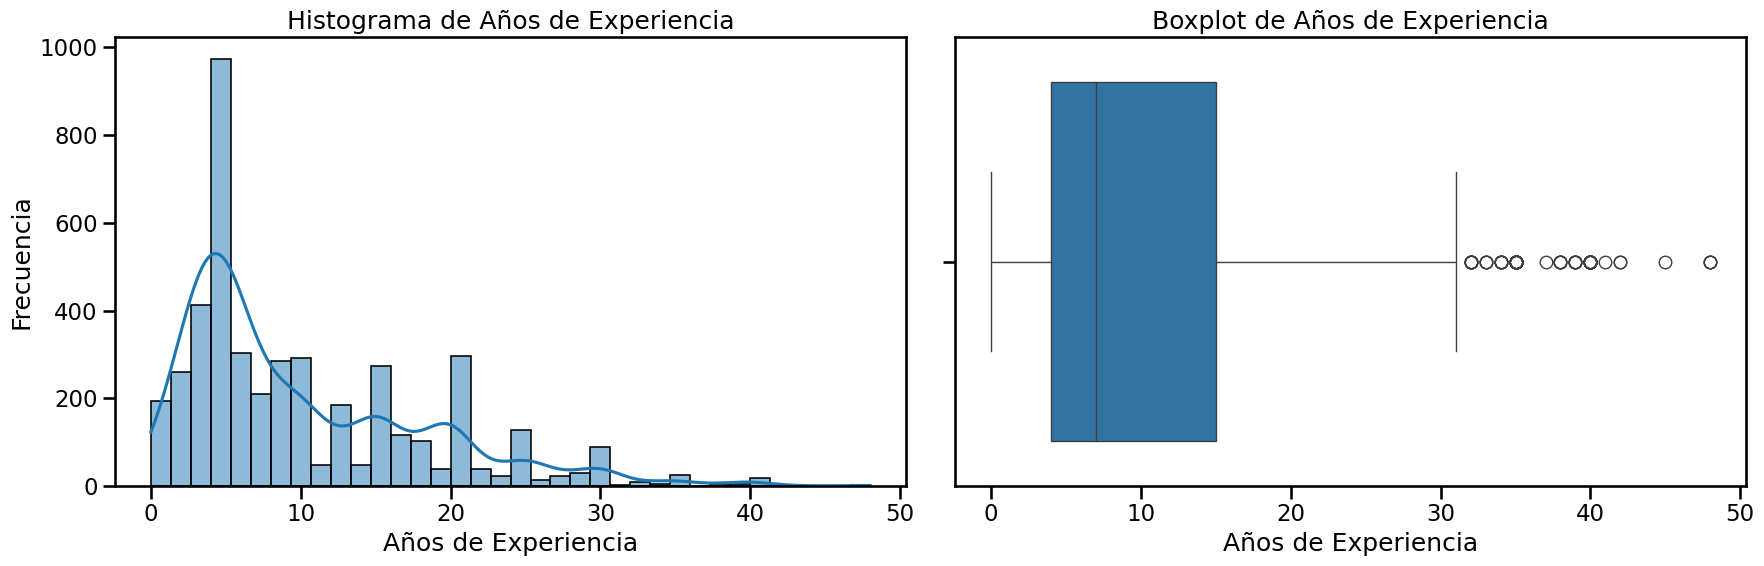

In [ ]:
# VISUALIZAMOS LOS AÑOS DE EXPERIENCIA

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Histograma en el panel izquierdo
seaborn.histplot(df1['profile_years_experience'], kde=True, ax=axes[0])
axes[0].set_title('Histograma de Años de Experiencia')
axes[0].set_xlabel('Años de Experiencia')
axes[0].set_ylabel('Frecuencia')

# Boxplot en el panel derecho
seaborn.boxplot(x=df1['profile_years_experience'], ax=axes[1])
axes[1].set_title('Boxplot de Años de Experiencia')
axes[1].set_xlabel('Años de Experiencia')

plt.tight_layout()
plt.show()

### Filtrado de las columnas numéricas
Establecemos criterios para el filtrado de las variables numéricas
* Vamos a utilizar el criterio de los rangos de 357800 a 20M para el neto (usado en punto 1)
* Vamos a usar el mismo criterio para el bruto con un rango amlpliado hasta 25M
* Límites de IQR para los años de experiencia

Por ultimo vemos el tamaño del dataframe filtrado

In [ ]:
# Tomamos de referencia el dataframe original
df_clean = df_raw.copy()

# Filtro para NETO
df_clean = df_clean[
    df_clean['salary_monthly_NETO'].between(357800, 20000000) &
    df_clean['salary_monthly_BRUTO'].between(357800, 25000000)
]

# Función para filtro IQR
def iqr_filter(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return series.between(q1 - 1.5 * iqr, q3 + 1.5 * iqr)

# Aplicar filtros IQR
mask = iqr_filter(df_clean['profile_years_experience'])

df_clean = df_clean[mask]

print('Tamaño del dataframe limpio', df_clean.shape)
print(f"Porcentaje del dataframe respecto al original {4565/4939*100:.2f}%")

Tamaño del dataframe limpio (4565, 60)
Porcentaje del dataframe respecto al original 92.43%


### Analizamos las columnas categóricas

In [ ]:
print(df_clean['profile_gender'].value_counts())

profile_gender
Hombre Cis           3560
Mujer Cis             917
Prefiero no decir      49
No binarie             19
Queer                  10
Trans                   8
Agénero                 1
Name: count, dtype: int64


Las categorias "prefiero no decir", "No binarie", "Queer", "Trans" y "Agénero" son muestras tan pequeñas que las vamos a agrupar en una sola categoria "Otro" y esta pasa a representar menos del 2% de los datos.

In [ ]:
new_gender = {
    'Hombre Cis': 'Hombre Cis',
    'Mujer Cis': 'Mujer Cis',
    'Prefiero no decir': 'Otro',
    'No binarie': 'Otro',
    'Queer': 'Otro',
    'Trans': 'Otro',
    'Agénero': 'Otro'
}
df_group_gender = df_clean.profile_gender.replace(new_gender)
df_clean_gender = df_clean.copy()
df_clean_gender['profile_gender'] = df_group_gender
print(df_clean_gender['profile_gender'].value_counts())

profile_gender
Hombre Cis    3560
Mujer Cis      917
Otro            87
Name: count, dtype: int64


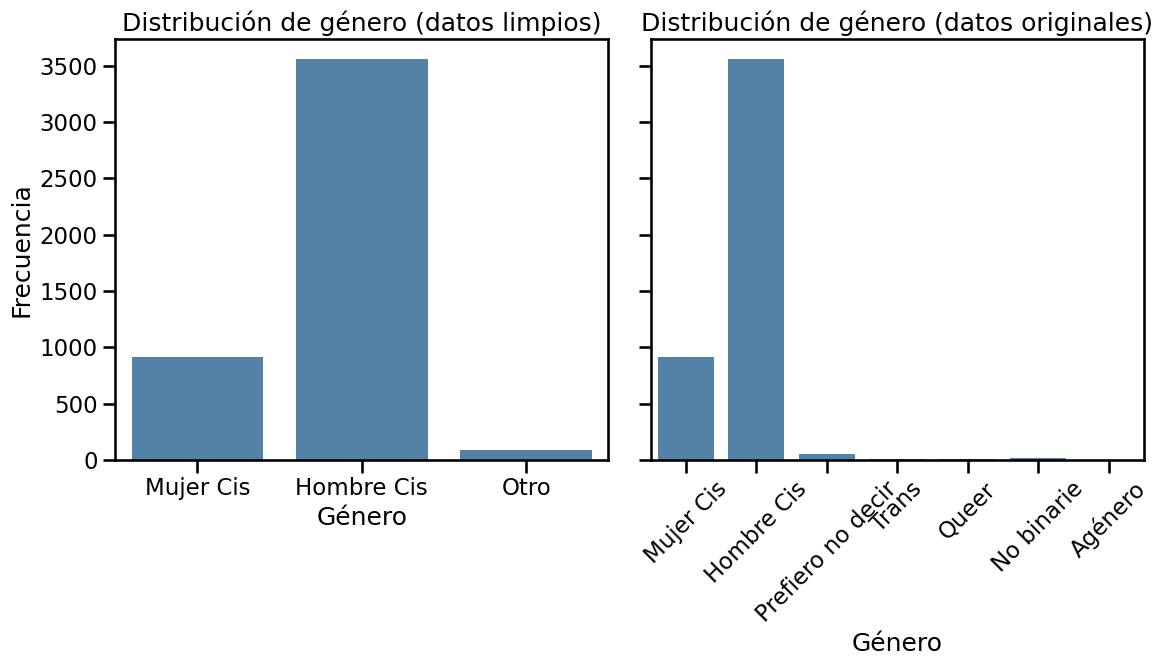

In [ ]:
# Visualizamos las categorías de género
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12,7), sharey=True)
# Panel 1 renombrados
seaborn.countplot(x='profile_gender', data=df_clean_gender, color='steelblue', ax=ax[0])
ax[0].set_xlabel('Género')
ax[0].set_ylabel('Frecuencia')
ax[0].set_title('Distribución de género (datos limpios)')
ax[0].tick_params(axis='x', rotation=0)


# Panel 2 originales
seaborn.countplot(x='profile_gender', data=df_clean, color='steelblue', ax=ax[1])
ax[1].set_xlabel('Género')
ax[1].set_ylabel('Frecuencia')
ax[1].set_title('Distribución de género (datos originales)')
ax[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

En este gráfico se observa que la mayoría de las personas que respondieron la encuesta son hombres cis (78%), seguido por mujeres (20%) cis, y un 2% el resto de categorias.

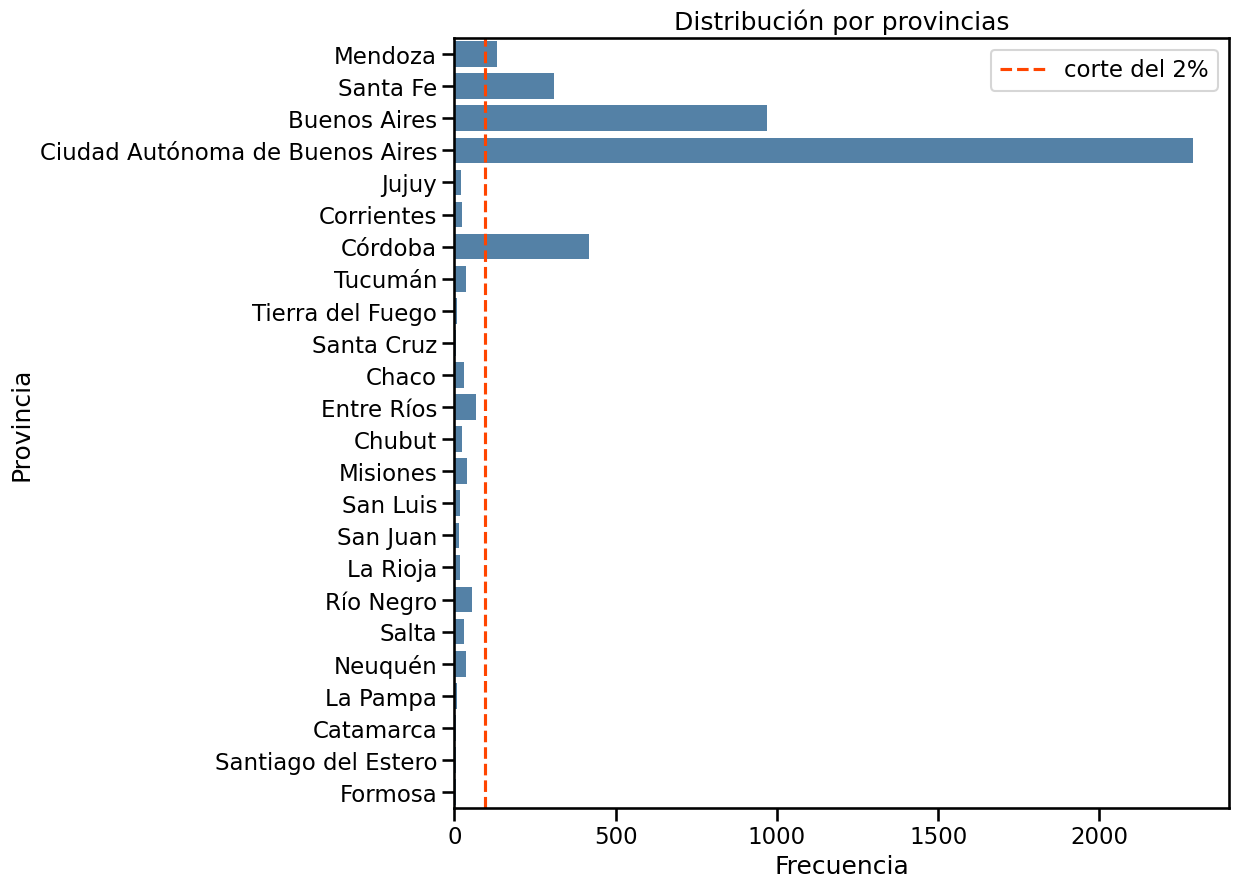

In [ ]:
# Visualizamos las provincias

fig = plt.figure(figsize=(10, 10))
plt.axvline(4700*0.02,
            color='orangered', linestyle='--', label='corte del 2%')
seaborn.countplot(y=df_clean['work_province'], color='steelblue')
plt.xlabel('Frecuencia')
plt.ylabel('Provincia')
plt.title('Distribución por provincias')
plt.legend()
plt.show()

Observamos que la mayoría de las personas que respondieron la encuesta están concentradas en Buenos Aires, CABA, Córdoba, Santa Fé y Mendoza, miestras que las otras provincias representan fracciones menores al 2%. Por esto decidimos establecer el criterio de agrupar estas provincias en una sola categoría "otras provincias".

In [ ]:
# Armamos un diccionario para renombrar las categorias de provincias
new_prov = {
    'Buenos Aires': 'Buenos Aires',
    'Ciudad Autónoma de Buenos Aires': 'CABA',
    'Catamarca': 'otras provincias',
    'Chaco': 'otras provincias',
    'Chubut': 'otras provincias',
    'Córdoba': 'Córdoba',
    'Corrientes': 'otras provincias',
    'Entre Ríos': 'otras provincias',
    'Formosa': 'otras provincias',
    'Jujuy': 'otras provincias',
    'La Pampa': 'otras provincias',
    'La Rioja': 'otras provincias',
    'Mendoza': 'Mendoza',
    'Misiones': 'otras provincias',
    'Neuquén': 'otras provincias',
    'Río Negro': 'otras provincias',
    'Salta': 'otras provincias',
    'San Juan': 'otras provincias',
    'San Luis': 'otras provincias',
    'Santa Cruz': 'otras provincias',
    'Santa Fe': 'Santa Fe',
    'Santiago del Estero': 'otras provincias',
    'Tierra del Fuego': 'otras provincias',
    'Tucumán': 'otras provincias',
}

df_group_province = df_clean_gender.work_province.replace(new_prov)
df_clean_province = df_clean_gender.copy()
df_clean_province['work_province'] = df_group_province
print(df_clean_province['work_province'].value_counts())

work_province
CABA                2289
Buenos Aires         970
otras provincias     449
Córdoba              417
Santa Fe             309
Mendoza              131
Name: count, dtype: int64


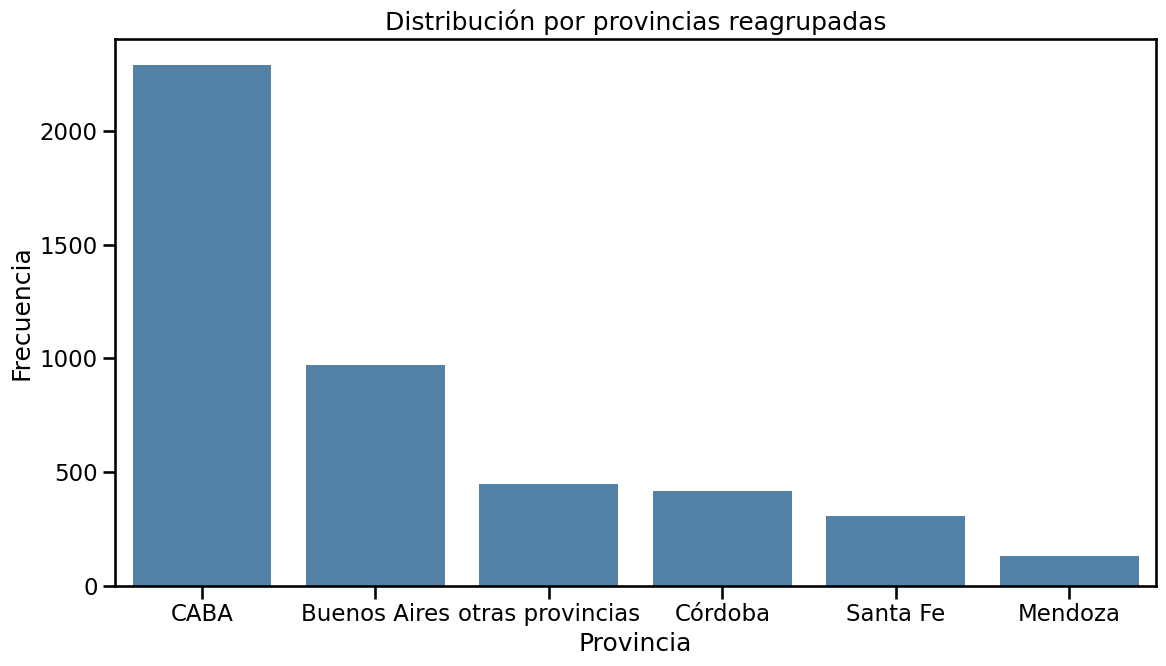

In [ ]:
# Visualizamos las nuevas categorías de provincias
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(12,7), sharey=True)
# Panel 1 renombrados
seaborn.countplot(x='work_province', data=df_clean_province, color='steelblue', order=df_clean_province['work_province'].value_counts().index, ax=ax)
ax.set_xlabel('Provincia')
ax.set_ylabel('Frecuencia')
ax.set_title('Distribución por provincias reagrupadas')
ax.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

### Análisis entre variables

Primero vamos a hacer un análisis entre variables numéricas usando gráficos de dispersión

/tmp/ipykernel_1052/601432288.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


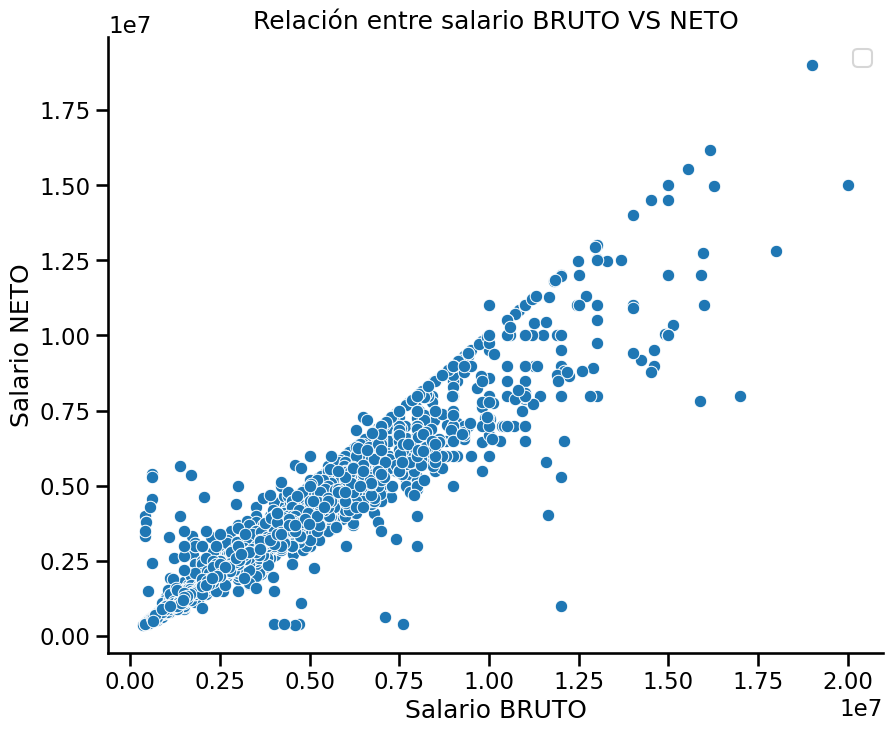

In [ ]:
plt.figure(figsize=(10, 8))

seaborn.scatterplot(x = df_clean['salary_monthly_BRUTO'], y=df_clean['salary_monthly_NETO'])

plt.legend()
plt.title('Relación entre salario BRUTO VS NETO')
plt.xlabel('Salario BRUTO')
plt.ylabel('Salario NETO')
seaborn.despine()

plt.show()

Se observa que hay una correlacion casi lineal creciente entre los datos, lo cual tiene sentido porque el neto es una fraccion del bruto.
Además, notamos que hay puntos en los que el salario NETO supera el salario BRUTO, lo cual no tiene sentido. Además, tendremos en cuenta que los descuentos sobre el BRUTO son de alrededor del 20%, entonces, filtraremos los datos que correspondan a salarios netos cuyos descuentos sobre el bruto superan el 30%.

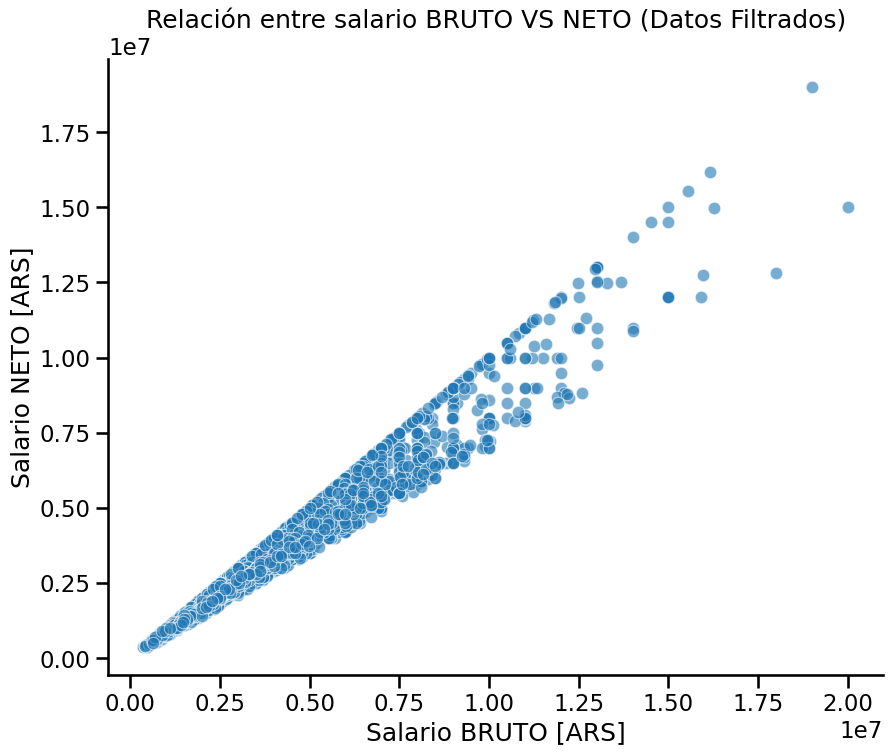

In [ ]:
# Filtrar los datos donde el salario bruto es menor que el salario neto
df_filtered_salary = df_clean[(df_clean['salary_monthly_BRUTO'] >= df_clean['salary_monthly_NETO']) & (df_clean['salary_monthly_BRUTO']*0.7 <= df_clean['salary_monthly_NETO'])].copy()

plt.figure(figsize=(10, 8))

seaborn.scatterplot(x=df_filtered_salary['salary_monthly_BRUTO'], y=df_filtered_salary['salary_monthly_NETO'], alpha=0.6)

plt.title('Relación entre salario BRUTO VS NETO (Datos Filtrados)')
plt.xlabel('Salario BRUTO [ARS]')
plt.ylabel('Salario NETO [ARS]')
seaborn.despine()

plt.show()

In [ ]:
print('Tamaño del dataframe limpio', df_filtered_salary.shape)
print(f"Porcentaje del dataframe respecto al original {4231/4939*100:.2f}%")

Tamaño del dataframe limpio (4231, 60)
Porcentaje del dataframe respecto al original 85.67%


/tmp/ipykernel_1052/1543972583.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


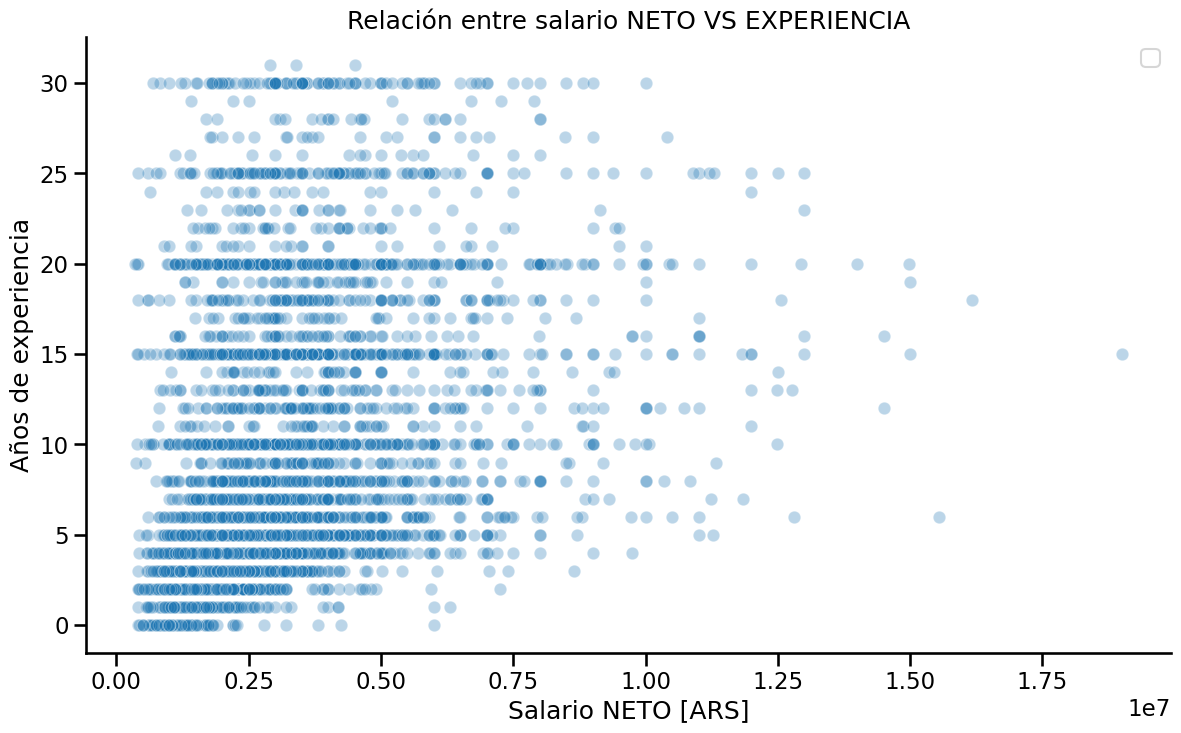

In [ ]:
plt.figure(figsize=(14, 8))

seaborn.scatterplot(x = df_clean['salary_monthly_NETO'], y=df_clean['profile_years_experience'], alpha=0.3)

plt.legend()
plt.title('Relación entre salario NETO VS EXPERIENCIA')
plt.xlabel('Salario NETO [ARS]')
plt.ylabel('Años de experiencia')
seaborn.despine()

plt.show()

Como en el scatterplot hay tendencia a que los datos se superpongan, añadimos transparencia para poder visualizar los puntos donde los datos son mas densos.
Por otro lado, observamos que dentro de los 10 años de experiencia si hay una tendencia a cobrar mejor. Sin embargo, cuando aumentan los años de experiencia esta tendencia no es tan clara. También observamos que mucha gente tiende a contestar una cantidad redonda de años de experiencia (10, 15, 20, 25, 30 ...), lo que la hace parecer una variable aún más discretizada.

Para visualizar mejor la tendencia en los primeros años de experiencia, hacemos un grafico reducido.

/tmp/ipykernel_1052/3277011026.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


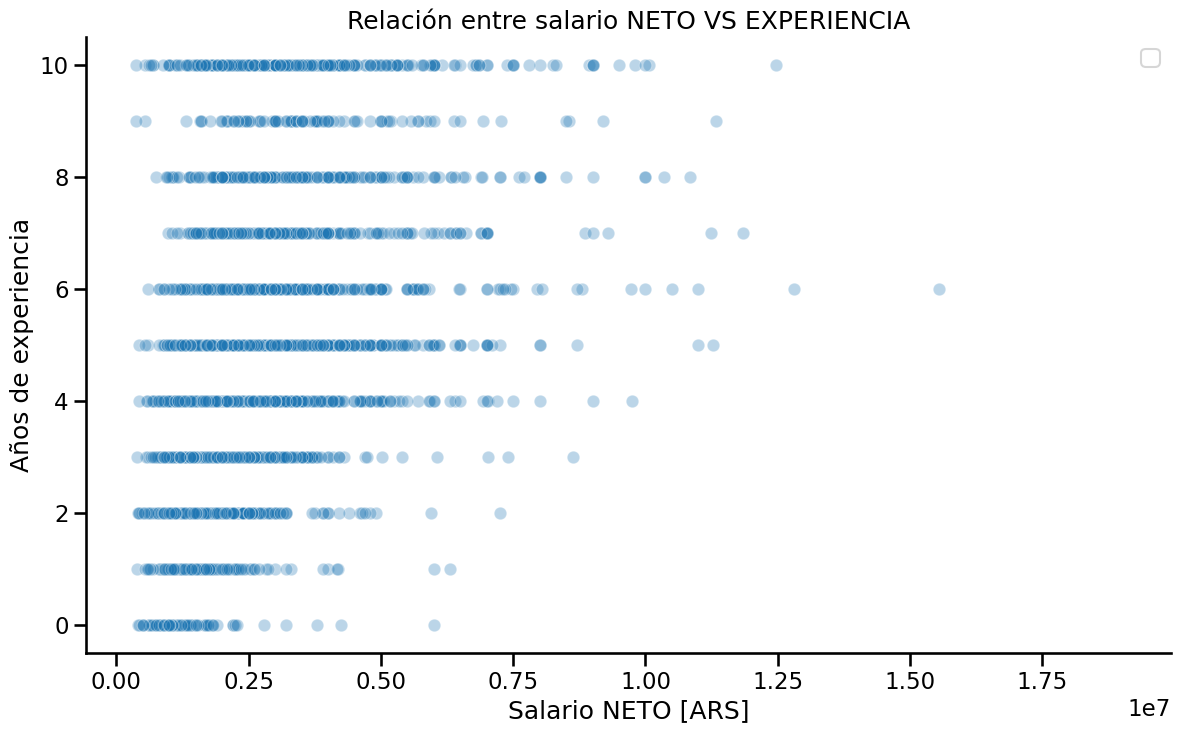

In [ ]:
plt.figure(figsize=(14, 8))

seaborn.scatterplot(x = df_clean['salary_monthly_NETO'], y=df_clean['profile_years_experience'], alpha=0.3)

plt.legend()
plt.title('Relación entre salario NETO VS EXPERIENCIA')
plt.xlabel('Salario NETO [ARS]')
plt.ylabel('Años de experiencia')
plt.ylim(-0.5 , 10.5)
seaborn.despine()

plt.show()

## Visualización de variables categóricas vs numéricas

Analizamos la relación del salario según la provincia y nos preguntamos si hay provincias donde se cobra mejor

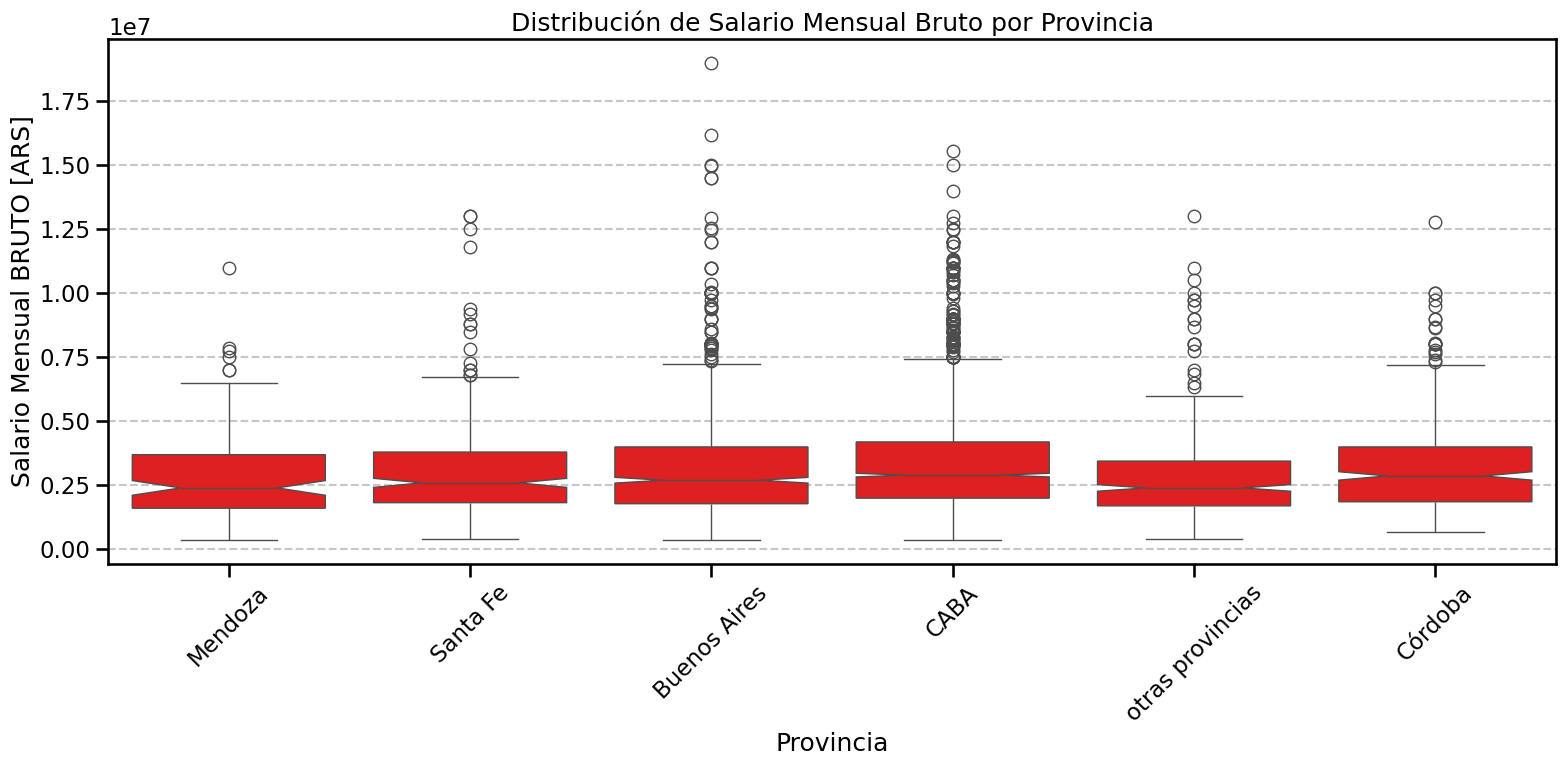

In [ ]:

plt.figure(figsize=(16, 8))
seaborn.boxplot(data=df_clean_province, x='work_province', y='salary_monthly_NETO', color='red', notch=True)
plt.title('Distribución de Salario Mensual Bruto por Provincia')
plt.xlabel('Provincia')
plt.ylabel('Salario Mensual BRUTO [ARS]')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


Para visualizar mejor las medianas con respecto a los intervalos de confianza haremos un zoom.

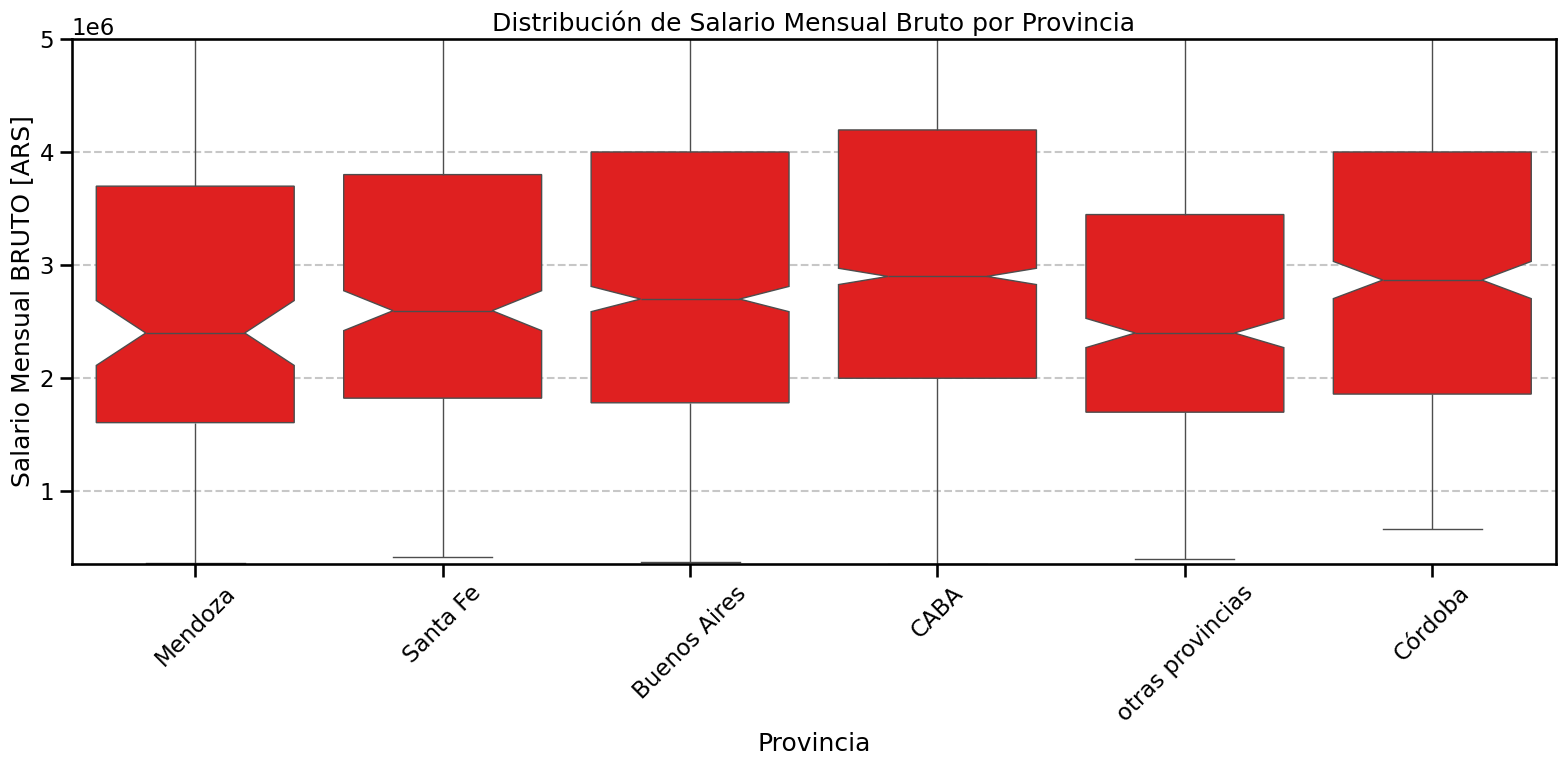

In [ ]:

plt.figure(figsize=(16, 8))
seaborn.boxplot(data=df_clean_province, x='work_province', y='salary_monthly_NETO', color='red', notch=True)
plt.title('Distribución de Salario Mensual Bruto por Provincia')
plt.xlabel('Provincia')
plt.ylabel('Salario Mensual BRUTO [ARS]')
plt.ylim(357800, 5E6)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Observando este gráfico vemos que, por un lado no hay tanta diferencia de salario entre provincias, pero que si hay una tendencia a que CABA y Córdoba tengan salarios un poco mayores.

La mediana de CABA es distinguible con todas las categorias salvo Córdoba.

Por otro lado, graficamos la distribución del salario según género para ver si hay desigualdad salarial.

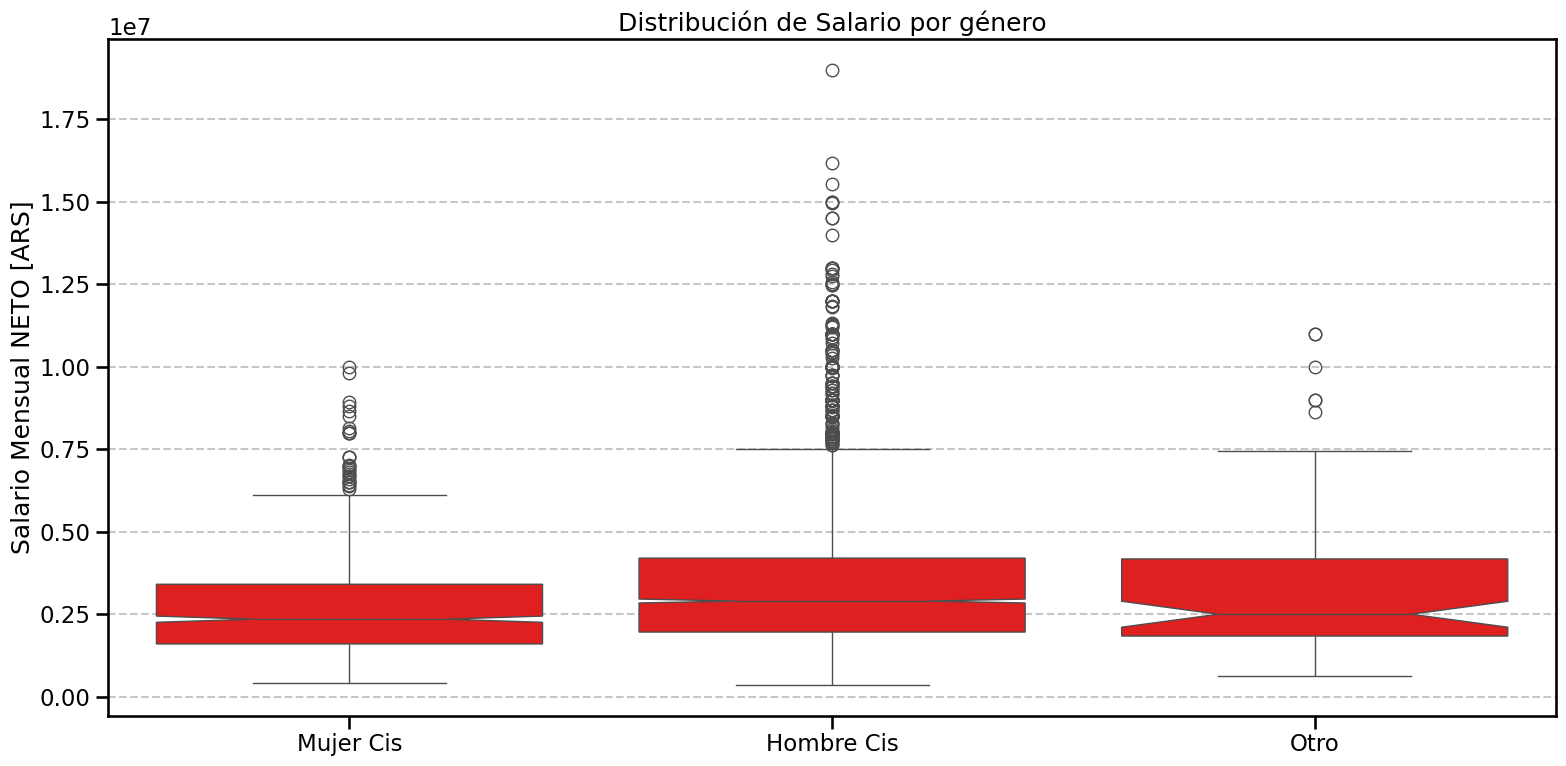

In [ ]:
plt.figure(figsize=(16, 8))
seaborn.boxplot(data=df_clean_gender, x='profile_gender', y='salary_monthly_NETO', color='red', notch=True)
plt.title('Distribución de Salario por género')
plt.xlabel('')
plt.ylabel('Salario Mensual NETO [ARS]')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


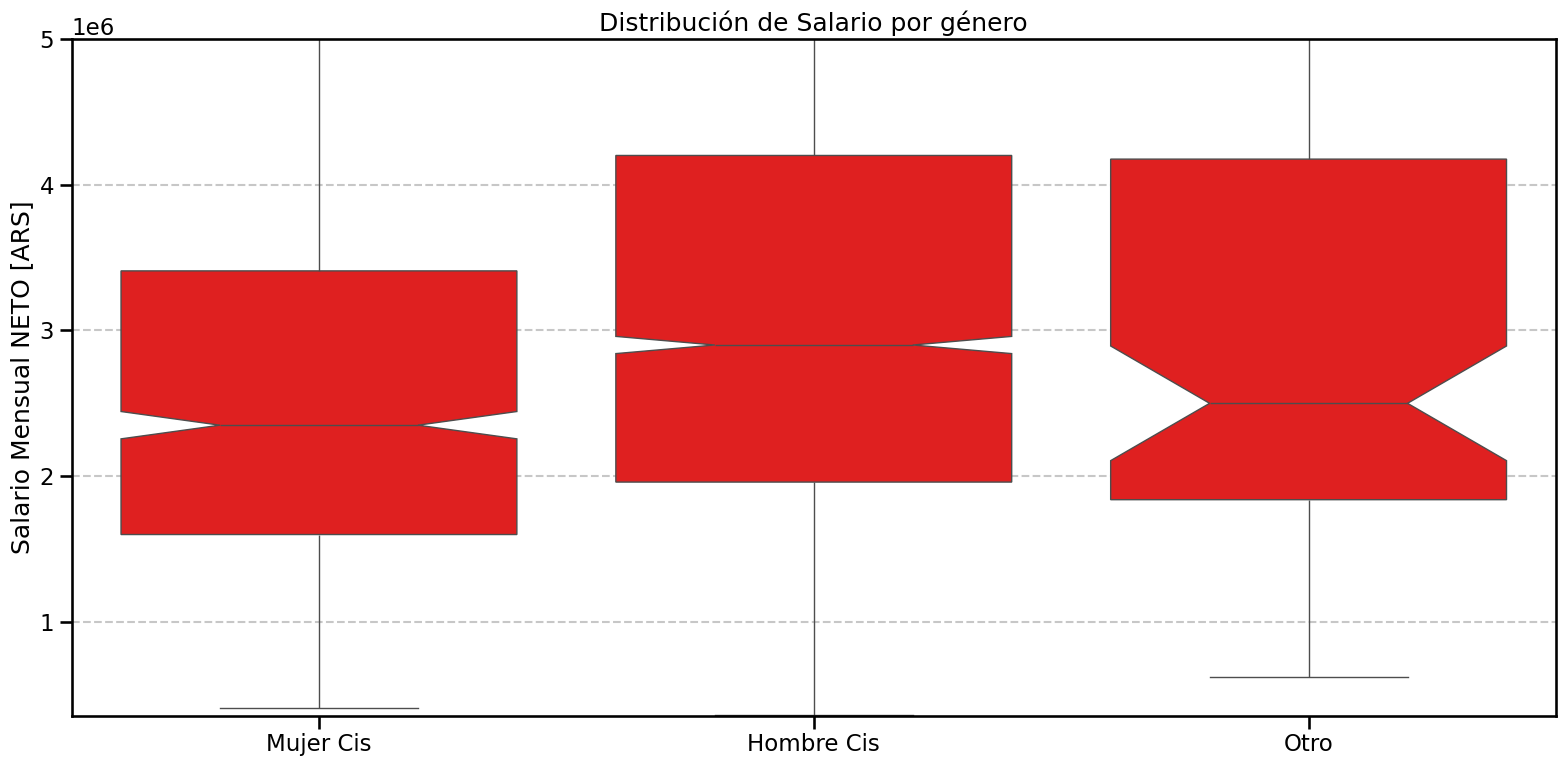

In [ ]:
# Zoom para visualizar mejor las medianas con los intervalos de confianza
plt.figure(figsize=(16, 8))
seaborn.boxplot(data=df_clean_gender, x='profile_gender', y='salary_monthly_NETO', color='red', notch=True)
plt.title('Distribución de Salario por género')
plt.xlabel('')
plt.ylabel('Salario Mensual NETO [ARS]')
plt.ylim(357800, 5E6)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Vemos que la mediana del salario de los hombres cis es mayor, mientras que la distribución general de las mujeres cis está corrida a salarios menores, aún más que la categoría 'Otro'.

Vemos que la mediana del salario de los hombres cis es distinguible para mujeres cis, mientras que para la categoría "Otro" al ser una muestra reducida presenta un intervalo de confianza grande que se solapa con las otras dos categorias.

Graficamos la distribucion de años de experiencia VS Género intentando responder la pregunta de si las mujeres se han incorporado al rubro de la programación en los últimos años.

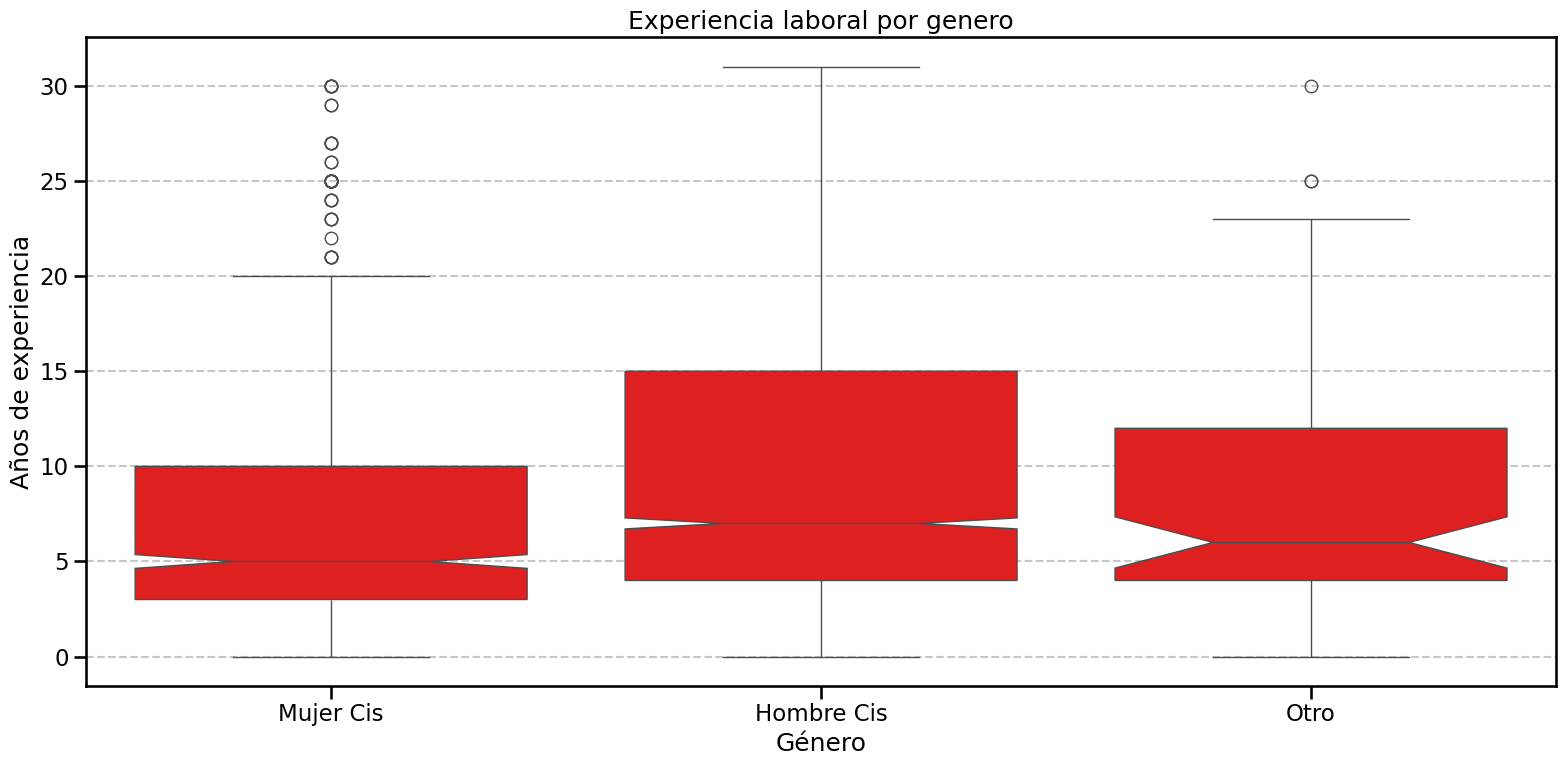

In [ ]:
plt.figure(figsize=(16, 8))
seaborn.boxplot(data=df_clean_province, x='profile_gender', y='profile_years_experience', color='red', notch = True)
plt.title('Experiencia laboral por genero')
plt.xlabel('Género')
plt.ylabel('Años de experiencia')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Observamos que los hombres cis tienen experiencias entre 0 y 40 años, mientras que las mujeres entre 0 y 20. Esto nos puede dar una pista de que las mujeres se han incorporado más recientemente al rubro.

## Conclusiones sobre el punto 2(a)

Primero hicimos un análisis descriptivo de cada una de las variables por separado y, además, separando entre variables numéricas y categóricas.

1. **Variables numéricas:** Para el caso del **salario NETO**, en el punto anterior ya habíamos hecho un análisis descriptivo de esta variable y usamos el criterio del punto 1 de filtrar salarios entre aproximadamente 300k y 20M. El mismo procedimiento se aplicó luego para el **salario BRUTO**. Para el caso de **Años de experiencia** usamos el criterio IQR, que nos dejó un rango de 0 a aproximadamente 31 años.


2. **Variables categóricas:** Para el análisis de variables categóricas, en primer lugar se analizó la fecuencia de cada categoría. A partir de esto, se observó que algunas categorías concentraban una gran cantidad de cuentas, mientras que otras representaban una proporción muy pequeña del total. Dado que estas categorías poco frecuentes no son representativas, se consideró que su análisis individual no resulta informativo, especialmente al explorar relaciones con otras variables. Por este motivo, se decidió agruparlas de manera conveniente, reduciendo la cantidad de categorías y conservando aquellas más representativas. Esto permite obtener resultados más claros y comparaciones más consistentes en una primera instancia del análisis.

**Análisis entre variables**

- Primero hicimos un scatterplot del salario BRUTO y NETO, observamos una relación aproximadamente lineal entre ambas variables. En este punto decidimos trabajar solo con el salario NETO.  Además, hicimos un análisis de la relación entre el salario BRUTO y NETO teniendo en cuenta que el salario NETO corresponde a aproximadamente un 80% del salario BRUTO.
- También analizamos la relación entre el salario y los años de experiencia. No se observó una tendencia general clara, pero si acotamos el rango de 0 a 10 años de experiencia si se ve un incremento en el salario.

Utilizamos boxplots para analizar la relación entre salario y provincia, salario y género, y género y años de experiencia. El objetivo fue responder a tres preguntas:

¿Hay provincias en las que se cobra más?
¿Hay un género que cobra más?
¿Se han incorporado más mujeres a este tipo de trabajo?

Los boxplots permiten analizar la relación entre variables categóricas y numéricas, ya que muestran cómo se distribuye una variable (en este caso, el salario) dentro de cada categoría. A través de estos gráficos se pueden observar medidas como la mediana, la dispersión y la presencia de valores atípicos.

De esta manera, es posible comparar los salarios entre distintas categorías sin que el análisis dependa únicamente de la cantidad de observaciones en cada grupo. Sin embargo, se tuvo en cuenta que las categorías con muy pocos datos pueden no ser representativas, por lo que previamente se agruparon aquellas menos frecuentes.

A partir de este análisis, se observó que los salarios más altos se encuentran en CABA, que los hombres presentan mayores salarios que las mujeres cis, y que la mediana de años de experiencia en mujeres cis es de aproximadamente 5 años, mientras que valores superiores a 10 años aparecen como casos extremos. Esto sugiere que la mayoría de las mujeres se ha incorporado a este tipo de trabajo en los últimos años.


## Punto b)
En primera instancia, visualizamos conjuntamente las dos variables numéricas.

/tmp/ipykernel_1052/3534131410.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


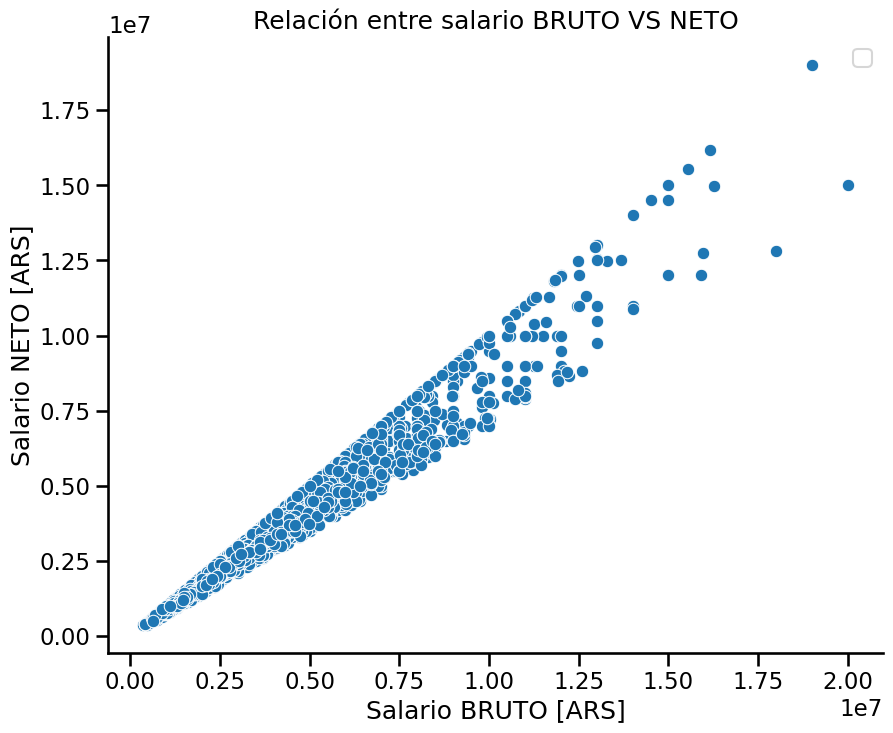

In [ ]:
plt.figure(figsize=(10, 8))

seaborn.scatterplot(x = df_filtered_salary['salary_monthly_BRUTO'], y=df_filtered_salary['salary_monthly_NETO'])

plt.legend()
plt.title('Relación entre salario BRUTO VS NETO')
plt.xlabel('Salario BRUTO [ARS]')
plt.ylabel('Salario NETO [ARS]')
seaborn.despine()

plt.show()

Se puede observar claramente una correlación lineal positiva, sin embargo, para confirmar la tendencia, calculamos la correlación

In [ ]:
#corr=np.corrcoef(df_clean.salary_monthly_BRUTO,df_clean.salary_monthly_NETO)
#print('matriz de correlaciones: \n ', corr,'\n')

print('Correlación entra ambas variables: ',df_filtered_salary.salary_monthly_BRUTO.corr(df_clean.salary_monthly_NETO),'\n')

Correlación entra ambas variables:  0.979781292896952 



## Conclusiones sobre el punto 2(b):
Dado que la correlación es del 98%, podemos decir que las variables están fuertemente correlacionadas, lo que supone que podríamos prescindir de una de ellas. Sin embargo, si quisieramos discriminar entre distintos tipos de descuentos que puedan tener los empleados (por ejemplo, por trabajar para distintos paises), sería necesario agregar alguna información adicional.

## Punto c)
En primera instancia, queremos saber cuáles son los niveles de estudio más representativos.
Armamos un nuevo dataframe con las columnas relevantes, y evaluamos la cantidad de datos útiles en relación a ellas

In [ ]:
relevant_columns2 = ['profile_studies_level', 'salary_monthly_NETO','work_dedication']
df_astudies = df[relevant_columns2]
#df_astudies = df_astudies[(df_astudies['profile_studies_level'].notna()) & (df_astudies['salary_monthly_NETO'].notna())]
print("Cantidad de ingresos por nivel de estudio:")
print(df_astudies.profile_studies_level.value_counts())


# Cantidad de NaNs por variable
nan_counts = df_astudies.isna().sum()
print("\nCantidad de NaN por variable:")
print(nan_counts)

# Proporción de Nans
nan_proportions = df_astudies.isna().sum() / len(df)
print("\nProporción de NaN por variable:")
print(nan_proportions)

# Reemplazo con ceros para no tirar toda la fila
df_2c = df_astudies.fillna(0)

Cantidad de ingresos por nivel de estudio:
profile_studies_level
Universitario               1175
Terciario                    272
Maestría                     108
Posgrado/Especialización     108
Secundario                    65
Doctorado                     27
Posdoctorado                   6
Name: count, dtype: int64

Cantidad de NaN por variable:
profile_studies_level    3178
salary_monthly_NETO       222
work_dedication             0
dtype: int64

Proporción de NaN por variable:
profile_studies_level    0.643450
salary_monthly_NETO      0.044948
work_dedication          0.000000
dtype: float64


En este caso, observamos como la cantidad de personas que no respondieron a su nivel de estudio es del 64% del total del dataset, lo que supone que estaremos trabajando con una subpoblación mucho menor al total de la encuesta.

Filtramos nuevamente acorde al salario, y analizamos sólo la dedicación "Full-Time" para los dos niveles de estudio más relevantes

In [ ]:
interesting_studies = df_astudies.profile_studies_level.value_counts()[:2].index.tolist()
df2c= df_2c[(df_2c.profile_studies_level.isin(interesting_studies)) & (df_2c['salary_monthly_NETO'] < 20000000) &  (df_2c['salary_monthly_NETO'] > 300000) & (df_2c['work_dedication'] == 'Full-Time')].copy()

In [ ]:
print("Cantidad de ingresos por nivel de estudio:")
print(df2c.profile_studies_level.value_counts())

Cantidad de ingresos por nivel de estudio:
profile_studies_level
Universitario    1063
Terciario         243
Name: count, dtype: int64


Graficamos ambas distribuciones, para estudiar su (in)dependencia

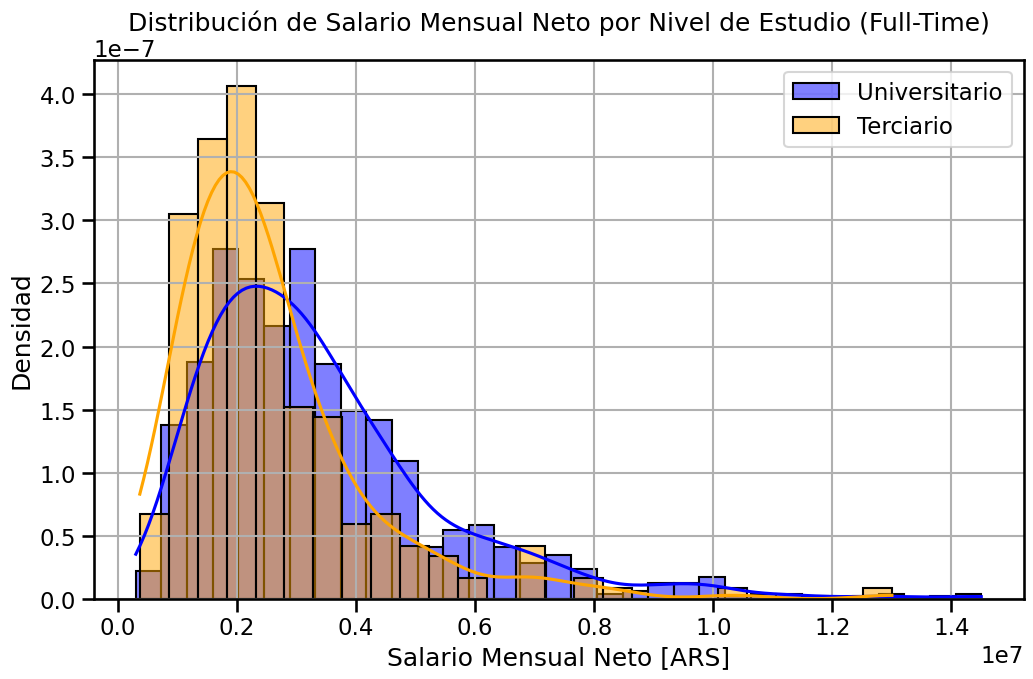

In [ ]:
universitario_salaries =df2c[df2c['profile_studies_level'] == 'Universitario']['salary_monthly_NETO']
terciario_salaries = df2c[df2c['profile_studies_level'] == 'Terciario']['salary_monthly_NETO']

plt.figure(figsize=(12, 7))
seaborn.histplot(universitario_salaries, color='blue', label='Universitario', kde=True, stat='density', alpha=0.5)
seaborn.histplot(terciario_salaries, color='orange', label='Terciario', kde=True, stat='density', alpha=0.5)

plt.title('Distribución de Salario Mensual Neto por Nivel de Estudio (Full-Time)')
plt.xlabel('Salario Mensual Neto [ARS]')
plt.ylabel('Densidad')
plt.legend()
plt.grid(True)
plt.show()


Y calculamos estadísticos descriptivos de cada distribución del salario según el nivel de estudio adquirido


In [ ]:
#medidas

# Universitarios
universitario_mean = universitario_salaries.mean()
universitario_median = universitario_salaries.median()
universitario_std = universitario_salaries.std()
universitario_q1 = universitario_salaries.quantile(0.25)
universitario_q3 = universitario_salaries.quantile(0.75)
universitario_iqr = universitario_q3 - universitario_q1

print("Estadísticos - Nivel Universitario:")
print(f"  Media: {universitario_mean:,.2f}")
print(f"  Mediana: {universitario_median:,.2f}")
print(f"  Desviación Estándar: {universitario_std:,.2f}")
print(f"  IQR: {universitario_iqr:,.2f}")

print("\n")

# Terciario
terciario_mean = terciario_salaries.mean()
terciario_median = terciario_salaries.median()
terciario_std = terciario_salaries.std()
terciario_q1 = terciario_salaries.quantile(0.25)
terciario_q3 = terciario_salaries.quantile(0.75)
terciario_iqr = terciario_q3 - terciario_q1

print("Estadísticos- Nivel Terciario:")
print(f"  Media: {terciario_mean:,.2f}")
print(f"  Mediana: {terciario_median:,.2f}")
print(f"  Desviación Estándar: {terciario_std:,.2f}")
print(f"  IQR: {terciario_iqr:,.2f}")

Estadísticos - Nivel Universitario:
  Media: 3,413,665.96
  Mediana: 3,000,000.00
  Desviación Estándar: 2,089,144.38
  IQR: 2,222,118.40


Estadísticos- Nivel Terciario:
  Media: 2,570,525.39
  Mediana: 2,170,000.00
  Desviación Estándar: 1,669,708.07
  IQR: 1,562,747.16


Al observar las distribuciones y los valores de estadísticos descriptivos, podemos suponer que las variables Nivel de Estudio y Salario Neto no son independientes, puesto que se observan medidas de tendencia central y dispersión distintas para las dos distribuciones estudiadas. Sin embargo, para poder evaluar esta aseveración de mejor manera, estudiaremos la probabilidad condicional de cobrar más que la media de salarios, siendo que se adquirió cierto nivel de estudios.

In [ ]:
overall_avg_salary = df2c['salary_monthly_NETO'].mean() #O MEDIA?
print(f"Mediana global del salario en el dataframe: {overall_avg_salary:,.2f}")

# Probabilidad de cobrar más que el promedio en nuestro dataframe
prob_overall_above_avg = len(df2c[df2c['salary_monthly_NETO'] > overall_avg_salary]) / len(df2c)
print(f"\nProbabilidad de cobrar más que el promedio: {prob_overall_above_avg:.4f}")

# Probabilidad condicional para Universitarios
prob_uni_above_avg = len(universitario_salaries[universitario_salaries > overall_avg_salary]) / len(universitario_salaries)
print(f"Probabilidad condicional de cobrar más que la media teniendo un título Universitario: {prob_uni_above_avg:.4f}")

# Probabilidad condicional para Terciarios
prob_terciario_above_avg = len(terciario_salaries[terciario_salaries > overall_avg_salary]) / len(terciario_salaries)
print(f"Probabilidad condicional de cobrar más que la media teniendo un título Terciario): {prob_terciario_above_avg:.4f}")

Mediana global del salario en el dataframe: 3,256,787.58

Probabilidad de cobrar más que el promedio: 0.3828
Probabilidad condicional de cobrar más que la media teniendo un título Universitario: 0.4205
Probabilidad condicional de cobrar más que la media teniendo un título Terciario): 0.2181


## Conclusiones sobre el punto 2(c):
Dado que:

 $$P(Salario Neto > Media) \neq P(Salario Neto > Media|Nivel de Estudios = Universitario)$$

 Podemos decir que ambas variables no son independientes.

**Además, observamos que la probabilidad de cobrar más teniendo un título universitario aumenta considerablemente.**

##Punto d)
Seleccionamos las variables numéricas de Salario Neto y Antiguedad, y como categórica el Nivel de Estudios.
Primero visualicemos las categorias de nivel de estudios.



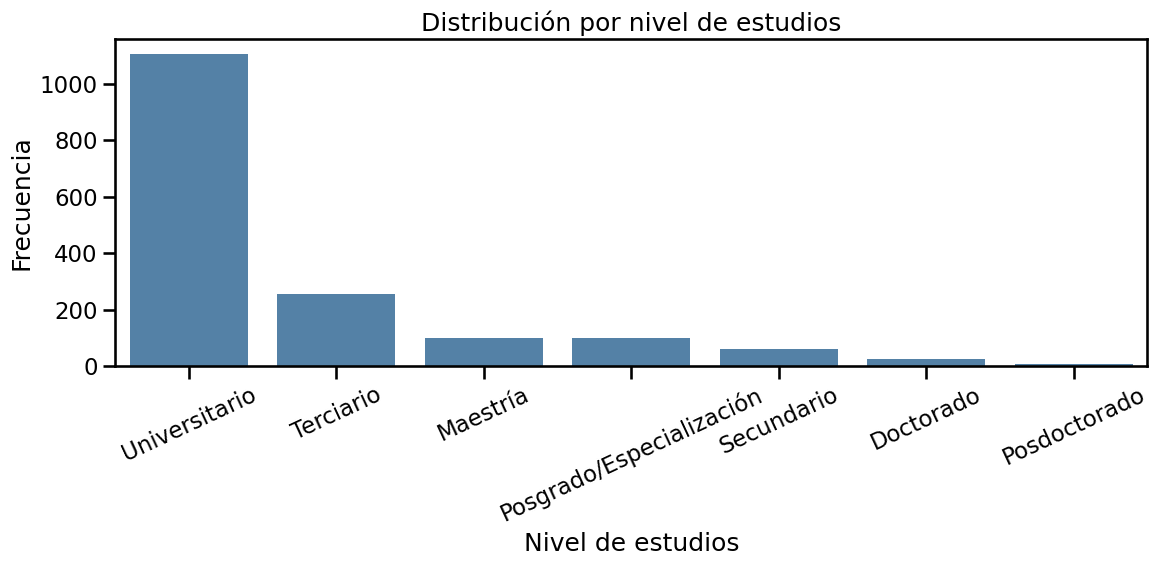

In [ ]:
# Visualizamos las categorías de estudios
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(12,6), sharey=True)
# Panel 1 renombrados
seaborn.countplot(x='profile_studies_level', data=df_clean, color='steelblue', order=df_clean_province['profile_studies_level'].value_counts().index, ax=ax)
ax.set_xlabel('Nivel de estudios')
ax.set_ylabel('Frecuencia')
ax.set_title('Distribución por nivel de estudios')
ax.tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()

Para hacer un análisis mas visualizable vamos a reducir las categorías a tres: pre-grado, grado y posgrado


In [ ]:
new_studies = {
    'Universitario': 'grado',
    'Terciario': 'pre-grado',
    'Maestría': 'posgrado',
    'Doctorado': 'posgrado',
    'Posgrado/Especialización': 'posgrado',
    'Secundario': 'pre-grado',
    'Posdoctorado': 'posgrado',
}
df_group_studies = df_clean.profile_studies_level.replace(new_studies)
df_clean_studies = df_clean.copy()
df_clean_studies['profile_studies_level'] = df_group_studies
print(df_clean_studies['profile_studies_level'].value_counts())

profile_studies_level
grado        1103
pre-grado     315
posgrado      228
Name: count, dtype: int64


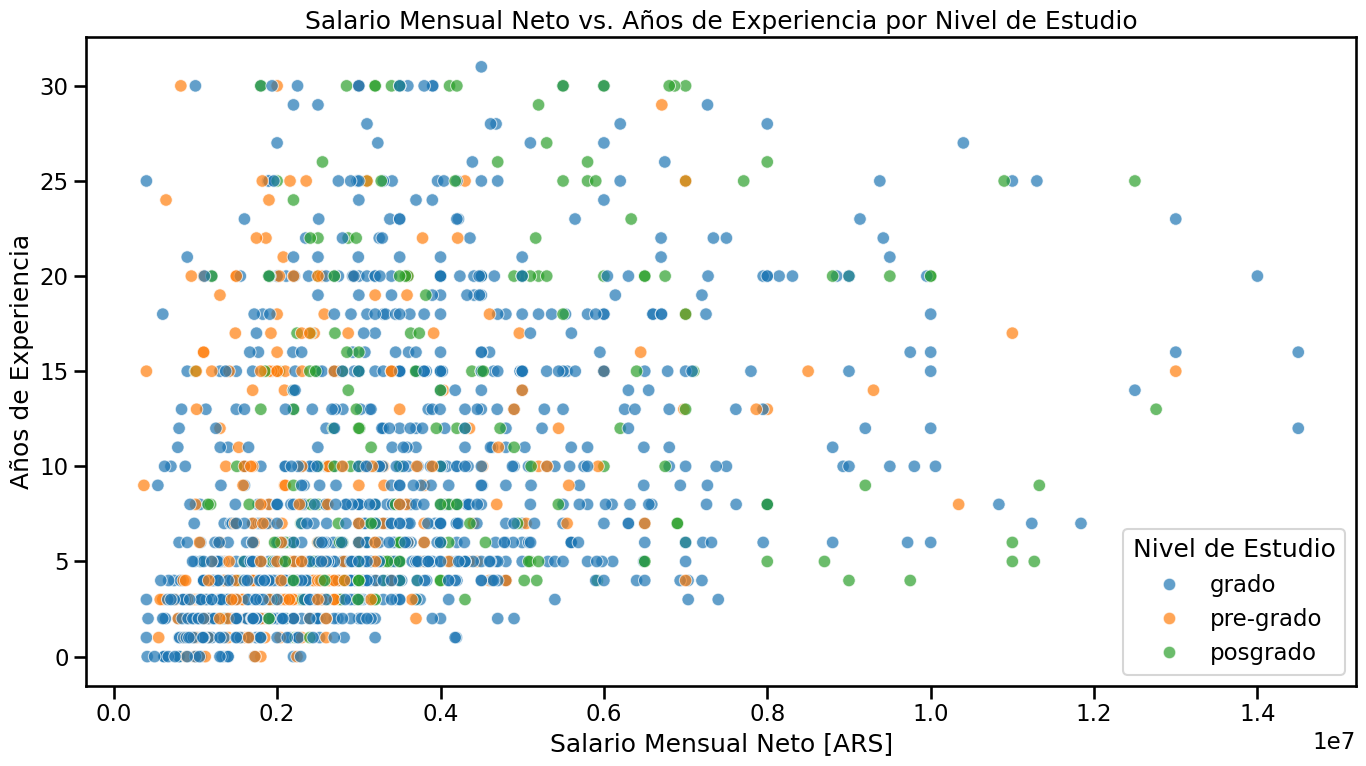

In [ ]:
plt.figure(figsize=(14, 8))

seaborn.scatterplot(
    data=df_clean_studies,
    x='salary_monthly_NETO',
    y='profile_years_experience',
    hue='profile_studies_level',
    palette='tab10',   # <- clave
    alpha=0.7
)

plt.title('Salario Mensual Neto vs. Años de Experiencia por Nivel de Estudio')
plt.xlabel('Salario Mensual Neto [ARS]')
plt.ylabel('Años de Experiencia')
plt.grid(False)
plt.legend(title='Nivel de Estudio')

plt.tight_layout()
plt.show()

## Conclusiones punto d)
Observamos que:
* Por un lado la gente con niveles de estudio más bajos tienen salarios más bajos y tienen una distribución de años de experiencia más amplia
* Los que tienen un posgrado tienen un piso de salario un poco mayor y una distribución de salario y años de experiencia dispersa en ambos casos.
* Por último, la gente con estudios de grado, que representan a la mayoria, muestra una correlación de salario creciente en función de la experiencia. Esto es más claro dentro de los primeros 10 años de experiencia.